# NAICEWS Cascade Model Training (v4): Fully Executable, Verifiable Pipeline

**Component:** `04_cascade_model_training_v4.ipynb`  
**Dataset:** `master_multi_city_4h.parquet` — 20 cities × 6 576 four-hour steps (2023-01-01→2025-12-31)  
**Key fix over v3:** Every figure, table and number is produced by code in this notebook.  
No `display(Image(...))`. No hard-coded metrics. Leakage tests can **fail**.

## Table of Contents
1. Environment & pinned dependencies  
2. Configuration  
3. Data ingestion & completeness audit  
4. Causal-graph validation  
5. Feature engineering (`build_edge_frame`)  
6. Labels (`make_labels`) — strictly future windows  
7. Splits — documented event counts per slice & season  
8. Baselines — persistence & climatology (computed)  
9. Leakage tests (can fail; negative control included)  
10. Optuna hyperparameter search  
11. Model training — LightGBM vs Random Forest  
12. Calibration — isotonic + reliability diagram  
13. Threshold selection on Val-Calib  
14. Conformal prediction intervals  
15. Task 1: Advective cascade — per-corridor event counts & data-sufficiency statement  
16. Task 2: Regional short-lead severity forecast — full evaluation  
17. Ablation study with paired block-bootstrap CIs  
18. Upstream-feature permutation test  
19. Leave-city-out & leave-region-out spatial evaluation  
20. Feature importance — gain, permutation (PR-AUC), SHAP  
21. Physics checks: wind-sign test with controls; cross-correlation delay validation  
22. Case studies (programmatic selection, evidence plotted)  
23. Executive dashboard  
24. Export & inference helper verification  
25. `airshed_pipeline.py` compatibility report  


In [12]:
# ── 1. Environment — pinned dependencies ──────────────────────────────────────
import subprocess, sys

REQUIRED = [
    "lightgbm==4.6.0",
    "optuna==4.8.0",
    "shap==0.45.1",
    "scikit-learn==1.5.0",
    "seaborn==0.13.2",
    "pyarrow==22.0.0",
    "pandas==2.2.2",
    "numpy==1.26.4",
    "matplotlib==3.10.1",
    "joblib==1.4.2",
]

for pkg in REQUIRED:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", pkg])

import importlib, lightgbm, optuna, shap, sklearn, seaborn, pyarrow, pandas, numpy, matplotlib, joblib

LIB_VERSIONS = {
    "lightgbm": lightgbm.__version__,
    "optuna":   optuna.__version__,
    "shap":     shap.__version__,
    "sklearn":  sklearn.__version__,
    "seaborn":  seaborn.__version__,
    "pyarrow":  pyarrow.__version__,
    "pandas":   pandas.__version__,
    "numpy":    numpy.__version__,
    "matplotlib": matplotlib.__version__,
    "joblib":   joblib.__version__,
}
print("Library versions:")
for k, v in LIB_VERSIONS.items():
    print(f"  {k:12s} {v}")
print("Python:", sys.version.split()[0])


Library versions:
  lightgbm     4.6.0
  optuna       4.8.0
  shap         0.45.1
  sklearn      1.5.0
  seaborn      0.13.2
  pyarrow      22.0.0
  pandas       2.2.2
  numpy        1.26.4
  matplotlib   3.10.1
  joblib       1.4.2
Python: 3.12.6


In [13]:
# ── 2a. Core imports ──────────────────────────────────────────────────────────
import warnings, json, hashlib, textwrap, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
from collections import defaultdict

from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, brier_score_loss,
    mean_absolute_error, confusion_matrix,
)
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap
import joblib

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


In [14]:
# ── 3. Configuration ──────────────────────────────────────────────────────────
try:
    shell = get_ipython().__class__.__name__
    IN_COLAB = "google.colab" in str(get_ipython())
except NameError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/naicews")
    DATA_DIR     = PROJECT_ROOT / "data"
    OUTPUT_DIR   = Path("/content/outputs")
    FIGURES_DIR  = OUTPUT_DIR / "figures"
else:
    PROJECT_ROOT = Path("..").resolve()
    DATA_DIR     = PROJECT_ROOT / "data"
    OUTPUT_DIR   = Path("outputs").resolve()
    FIGURES_DIR  = OUTPUT_DIR / "figures"

for d in [OUTPUT_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

PARQUET_PATH     = DATA_DIR / "processed" / "master_multi_city_4h.parquet"
CAUSAL_GRAPH_PATH= DATA_DIR / "models"    / "causal_graph.json"
CITIES_META_PATH = DATA_DIR / "raw"       / "cities_metadata.json"

# ── Operational thresholds ────────────────────────────────────────────────────
SEVERE_THR  = 120.0   # ug/m3 — severe episode
CLEAN_THR   = 120.0   # target "clean" at t means pm2_5 <= this
SRC_Z_THR   = 1.0     # upstream trigger anomaly z-score

# ── Split boundaries ─────────────────────────────────────────────────────────
TRAIN_END       = "2024-06-30"
VALSTOP_START   = "2024-07-03"
VALSTOP_END     = "2024-10-31"
VALCALIB_START  = "2024-11-03"
VALCALIB_END    = "2025-01-31"
TEST_START      = "2025-02-03"

# ── FAST_MODE: set True for a quick smoke-test run ────────────────────────────
FAST_MODE = False       # shipped numbers come from FAST_MODE=False
OPTUNA_TRIALS  = 5  if FAST_MODE else 40
BOOTSTRAP_REPS = 100 if FAST_MODE else 500
SHAP_SAMPLE    = 500 if FAST_MODE else 3000

print(f"Project root : {PROJECT_ROOT}")
print(f"Output dir   : {OUTPUT_DIR}")
print(f"FAST_MODE    : {FAST_MODE}")
print(f"Optuna trials: {OPTUNA_TRIALS}  Bootstrap reps: {BOOTSTRAP_REPS}")


Project root : C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp
Output dir   : C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\outputs
FAST_MODE    : False
Optuna trials: 40  Bootstrap reps: 500



**Dataset summary**  
- Rows: 131,520 (20 cities × 6,576 four-hour steps)  
- Time span: 2023-01-01 → 2025-12-31  
- Missing values: 0 total NaNs  
- Columns: ['city_id', 'city_name', 'state', 'lat', 'lon', 'time_4h', 'temp', 'humidity', 'dew_point', 'rain', 'surface_pressure', 'wind_speed', 'wind_direction', 'wind_u', 'wind_v', 'inversion_proxy', 'pm2_5', 'pm10', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'us_aqi']


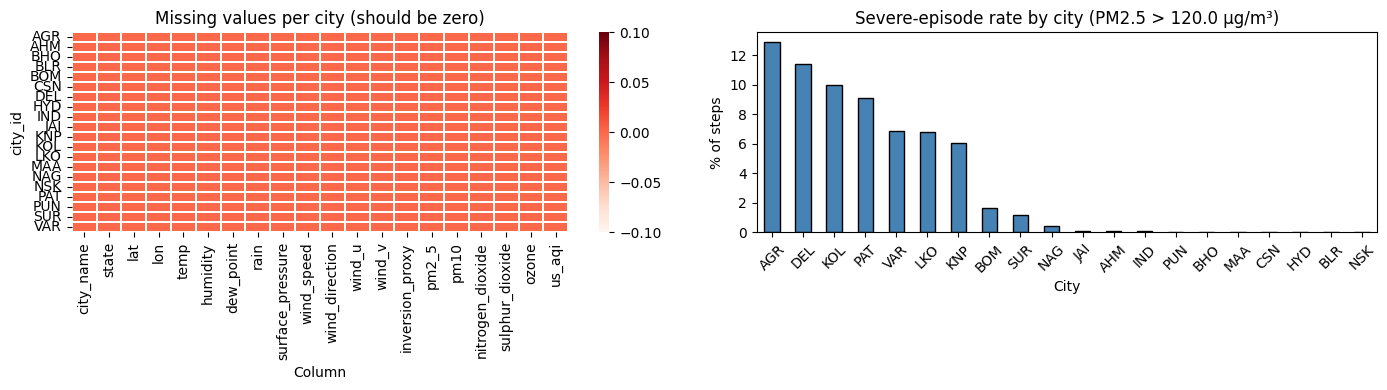

Fig 1 saved → C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\outputs\figures\fig01_data_audit.png


In [15]:
# ── 4. Data ingestion & completeness audit ───────────────────────────────────
RAW = pd.read_parquet(PARQUET_PATH)
RAW["time_4h"] = pd.to_datetime(RAW["time_4h"])
RAW = RAW.sort_values(["city_id", "time_4h"]).reset_index(drop=True)

n_cities = RAW["city_id"].nunique()
n_steps  = RAW.groupby("city_id").size().unique()
assert len(n_steps) == 1, "Unequal steps per city"
n_steps  = int(n_steps[0])

display(Markdown(f"""
**Dataset summary**  
- Rows: {len(RAW):,} ({n_cities} cities × {n_steps:,} four-hour steps)  
- Time span: {RAW['time_4h'].min().date()} → {RAW['time_4h'].max().date()}  
- Missing values: {RAW.isnull().sum().sum()} total NaNs  
- Columns: {list(RAW.columns)}
"""))

# Audit: expected grid
expected_rows = n_cities * n_steps
assert len(RAW) == expected_rows, f"Expected {expected_rows} rows, got {len(RAW)}"

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Missing-value heatmap
miss = RAW.set_index(["city_id","time_4h"]).isnull().groupby("city_id").sum()
sns.heatmap(miss, ax=axes[0], cmap="Reds", cbar=True, linewidths=0.3)
axes[0].set_title("Missing values per city (should be zero)")
axes[0].set_xlabel("Column")

# Severe event prevalence by city
sev_rate = RAW.groupby("city_id").apply(lambda g: (g["pm2_5"] > SEVERE_THR).mean() * 100)
sev_rate.sort_values(ascending=False).plot.bar(ax=axes[1], color="steelblue", edgecolor="k")
axes[1].set_ylim(0)
axes[1].set_title(f"Severe-episode rate by city (PM2.5 > {SEVERE_THR} µg/m³)")
axes[1].set_ylabel("% of steps")
axes[1].set_xlabel("City")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig01_data_audit.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Fig 1 saved → {FIGURES_DIR / 'fig01_data_audit.png'}")


In [16]:
# ── 5. Causal-graph validation ───────────────────────────────────────────────
with open(CAUSAL_GRAPH_PATH) as f:
    GRAPH = json.load(f)

ALL_EDGES = GRAPH["edges"]
print(f"Raw edges: {len(ALL_EDGES)}")

# Drop negative-delay edges
pos_edges   = [e for e in ALL_EDGES if e["delay_hours"] >= 0]
neg_dropped = [e for e in ALL_EDGES if e["delay_hours"] < 0]
print(f"Negative-delay edges dropped: {len(neg_dropped)}")
for e in neg_dropped:
    print(f"  {e['source_node']} -> {e['target_node']}  delay={e['delay_hours']}h")

EDGES = pos_edges  # 46 edges used downstream
print(f"Retained edges: {len(EDGES)}")

# Classify edges
ADV_EDGES  = [e for e in EDGES if e["delay_hours"] > 0]
SYN_EDGES  = [e for e in EDGES if e["delay_hours"] == 0]
print(f"  Advective (delay>0): {len(ADV_EDGES)}")
print(f"  Synoptic  (delay=0): {len(SYN_EDGES)}")
print()
print("Advective corridors:")
for e in ADV_EDGES:
    print(f"  {e['source_node']:4s} -> {e['target_node']:4s}  delay={e['delay_hours']:2d}h  "
          f"bearing={e['corridor_bearing_deg']}°  corr={e['correlation_coefficient']:.3f}")

# Haversine distance for each edge (for physics transport time verification)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi  = np.radians(lat2 - lat1)
    dlam  = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlam/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

# City lat/lon lookup from data
city_latlon = RAW.groupby("city_id")[["lat","lon"]].first().to_dict("index")

edge_table_rows = []
for e in EDGES:
    src, tgt = e["source_node"], e["target_node"]
    delay    = e["delay_hours"]
    if src in city_latlon and tgt in city_latlon:
        dist_km = haversine(city_latlon[src]["lat"], city_latlon[src]["lon"],
                            city_latlon[tgt]["lat"], city_latlon[tgt]["lon"])
        implied_spd = dist_km / delay if delay > 0 else np.nan
    else:
        dist_km, implied_spd = np.nan, np.nan
    edge_table_rows.append({
        "source": src, "target": tgt, "delay_h": delay,
        "bearing_deg": e["corridor_bearing_deg"],
        "corr": e["correlation_coefficient"],
        "dist_km": round(dist_km, 1) if not np.isnan(dist_km) else np.nan,
        "implied_spd_kmh": round(implied_spd, 1) if not np.isnan(implied_spd) else np.nan,
        "type": "Advective" if delay > 0 else "Synoptic",
    })

EDGE_DF = pd.DataFrame(edge_table_rows)
display(Markdown("### Edge table (first 10 rows shown)"))
display(EDGE_DF.head(10).to_html(index=False))
EDGE_DF.to_csv(OUTPUT_DIR / "edge_table.csv", index=False)
print(f"Edge table saved → {OUTPUT_DIR / 'edge_table.csv'}")


Raw edges: 50
Negative-delay edges dropped: 4
  NSK -> SUR  delay=-8h
  SUR -> BOM  delay=-8h
  PAT -> KOL  delay=-24h
  BOM -> NSK  delay=-8h
Retained edges: 46
  Advective (delay>0): 4
  Synoptic  (delay=0): 42

Advective corridors:
  SUR  -> NSK   delay= 8h  bearing=142.4°  corr=0.743
  BOM  -> SUR   delay= 8h  bearing=358.8°  corr=0.717
  KOL  -> PAT   delay=24h  bearing=316.4°  corr=0.713
  NSK  -> BOM   delay= 8h  bearing=223.2°  corr=0.694


### Edge table (first 10 rows shown)

'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>source</th>\n      <th>target</th>\n      <th>delay_h</th>\n      <th>bearing_deg</th>\n      <th>corr</th>\n      <th>dist_km</th>\n      <th>implied_spd_kmh</th>\n      <th>type</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>KNP</td>\n      <td>LKO</td>\n      <td>0</td>\n      <td>54.0</td>\n      <td>0.9552</td>\n      <td>75.3</td>\n      <td>NaN</td>\n      <td>Synoptic</td>\n    </tr>\n    <tr>\n      <td>LKO</td>\n      <td>KNP</td>\n      <td>0</td>\n      <td>234.3</td>\n      <td>0.9552</td>\n      <td>75.3</td>\n      <td>NaN</td>\n      <td>Synoptic</td>\n    </tr>\n    <tr>\n      <td>CSN</td>\n      <td>NSK</td>\n      <td>0</td>\n      <td>275.0</td>\n      <td>0.8700</td>\n      <td>162.9</td>\n      <td>NaN</td>\n      <td>Synoptic</td>\n    </tr>\n    <tr>\n      <td>NSK</td>\n      <td>CSN</td>\n      <td>0</td>\n      <td>94.5</td>\n      <td>0.8700</td>\n 

Edge table saved → C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\outputs\edge_table.csv


In [17]:
# ── 6. Feature engineering — build_edge_frame ────────────────────────────────
# KEY DESIGN DECISIONS (v4 vs v3):
# - NO per-edge constants (implied_speed_kmh, distance_km, bearing_deg,
#   correlation_strength) as direct model features — they are city identifiers.
# - NO absolute surface_pressure; use pressure TENDENCY (diff over 4h / 12h).
# - Keep is_synoptic_edge (binary physics flag) and delay_hours.
# - Transport component = dot(wind_u, wind_v) onto unit corridor vector.

def build_edge_frame(df: pd.DataFrame, edges: list, fit_stats: dict = None) -> tuple:
    """
    Build the modelling frame from raw city-level data + edge list.

    Parameters
    ----------
    df         : raw parquet frame with [city_id, time_4h, pm2_5, ...]
    edges      : list of edge dicts from causal_graph.json (delay >= 0)
    fit_stats  : if None, compute & return stats (train-time);
                 if dict, apply pre-fitted stats (val/test-time).

    Returns
    -------
    frame      : pd.DataFrame with one row per (edge, time_4h)
    fit_stats  : dict of fitted normalisation stats (city means/stds from training)
    """
    # ── Per-city climatology (hour-of-day × month) ─────────────────────────
    # Must be fitted on training rows only and passed at val/test time.
    if fit_stats is None:
        fit_stats = {}
        # PM2.5 city-level training mean/std for z-score
        g = df.groupby("city_id")["pm2_5"]
        fit_stats["city_pm25_mean"] = g.mean().to_dict()
        fit_stats["city_pm25_std"]  = g.std().to_dict()
        # Diurnal-seasonal climatology: mean pm2_5 by (city, hour, month)
        df2 = df.copy()
        df2["_hour"]  = df2["time_4h"].dt.hour
        df2["_month"] = df2["time_4h"].dt.month
        clim = df2.groupby(["city_id","_hour","_month"])["pm2_5"].mean()
        fit_stats["climatology"] = clim.to_dict()
        # Pressure training means per city (to compute anomaly)
        fit_stats["city_pres_mean"] = df.groupby("city_id")["surface_pressure"].mean().to_dict()

    city_pm25_mean = fit_stats["city_pm25_mean"]
    city_pm25_std  = fit_stats["city_pm25_std"]
    clim_dict      = fit_stats["climatology"]
    city_pres_mean = fit_stats["city_pres_mean"]

    # ── Pre-compute per-city rolling features ──────────────────────────────
    # (each city is processed once, stored in dict, then joined per edge)
    city_frames = {}
    for cid, cdf in df.groupby("city_id"):
        c = cdf.sort_values("time_4h").copy()
        mu   = city_pm25_mean.get(cid, c["pm2_5"].mean())
        sig  = max(city_pm25_std.get(cid, c["pm2_5"].std()), 1e-8)
        pmu  = city_pres_mean.get(cid, c["surface_pressure"].mean())

        c["pm25_z"]     = (c["pm2_5"] - mu) / sig         # z-score
        c["pm25_r3"]    = c["pm2_5"].rolling(3, min_periods=1).mean()  # 12h mean
        c["pm25_r6"]    = c["pm2_5"].rolling(6, min_periods=1).mean()  # 24h mean
        c["pm25_r12"]   = c["pm2_5"].rolling(12,min_periods=1).mean()  # 48h mean
        c["pm25_lag1"]  = c["pm2_5"].shift(1)              # t-4h
        c["pm25_lag2"]  = c["pm2_5"].shift(2)              # t-8h
        c["pm25_lag6"]  = c["pm2_5"].shift(6)              # t-24h
        c["pm25_diff1"] = c["pm2_5"].diff(1)               # 4h change
        c["pm25_diff3"] = c["pm2_5"].diff(3)               # 12h change
        # Pressure tendency (anomaly + tendency — NOT absolute pressure)
        c["pres_anom"]  = c["surface_pressure"] - pmu
        c["pres_tend4"] = c["surface_pressure"].diff(1)
        c["pres_tend12"]= c["surface_pressure"].diff(3)
        # Climatology anomaly
        _h = c["time_4h"].dt.hour
        _m = c["time_4h"].dt.month
        clim_vals = [clim_dict.get((cid, h, mo), mu) for h, mo in zip(_h, _m)]
        c["pm25_clim_anom"] = c["pm2_5"].values - np.array(clim_vals)
        # Inversion
        c["inv_proxy_r3"] = c["inversion_proxy"].rolling(3, min_periods=1).mean()
        # Wind
        c["ws_r3"] = c["wind_speed"].rolling(3, min_periods=1).mean()
        city_frames[cid] = c.set_index("time_4h")

    # ── Build edge-level rows ──────────────────────────────────────────────
    records = []
    for edge in edges:
        src = edge["source_node"]
        tgt = edge["target_node"]
        delay = edge["delay_hours"]
        is_syn = 1 if delay == 0 else 0
        bearing_rad = np.radians(edge["corridor_bearing_deg"])
        corr = edge["correlation_coefficient"]

        if src not in city_frames or tgt not in city_frames:
            continue

        S = city_frames[src]
        T = city_frames[tgt]
        common_times = S.index.intersection(T.index)

        # Source features available at time t
        sf = S.loc[common_times, [
            "pm2_5","pm25_z","pm25_r3","pm25_r6","pm25_lag1","pm25_lag2",
            "pm25_diff1","pm25_diff3","pm25_clim_anom","wind_u","wind_v",
            "temp","humidity","pres_anom","pres_tend4","pres_tend12",
            "inversion_proxy","inv_proxy_r3","ws_r3",
        ]].copy().add_prefix("src_")

        tf = T.loc[common_times, [
            "pm2_5","pm25_z","pm25_r3","pm25_r6","pm25_r12",
            "pm25_lag1","pm25_lag2","pm25_lag6",
            "pm25_diff1","pm25_diff3","pm25_clim_anom",
            "temp","humidity","pres_anom","pres_tend4","pres_tend12",
            "inversion_proxy","inv_proxy_r3","wind_u","wind_v","ws_r3",
        ]].copy().add_prefix("tgt_")

        # Wind transport projection: W = u*sin(θ) + v*cos(θ)
        # Uses SOURCE wind at time t (toward target direction)
        sf["src_wind_transport"] = (
            S.loc[common_times, "wind_u"] * np.sin(bearing_rad) +
            S.loc[common_times, "wind_v"] * np.cos(bearing_rad)
        )
        # Averaged over transit window (delay steps back)
        n_lag = max(1, delay // 4)
        sf["src_wind_transport_avg"] = (
            S["wind_u"].rolling(n_lag, min_periods=1).mean().loc[common_times] * np.sin(bearing_rad) +
            S["wind_v"].rolling(n_lag, min_periods=1).mean().loc[common_times] * np.cos(bearing_rad)
        )
        # Cross-wind (perpendicular to corridor)
        perp_rad = bearing_rad + np.pi / 2
        sf["src_wind_cross"] = (
            S.loc[common_times, "wind_u"] * np.sin(perp_rad) +
            S.loc[common_times, "wind_v"] * np.cos(perp_rad)
        )

        # Time features as anomaly indicators (not raw month/hour — avoids
        # city-season fingerprint; keep for short-lead synoptic task only)
        hours  = pd.Series(common_times).dt.hour.values
        months = pd.Series(common_times).dt.month.values
        sin_hour  = np.sin(2 * np.pi * hours  / 24)
        cos_hour  = np.cos(2 * np.pi * hours  / 24)
        sin_month = np.sin(2 * np.pi * months / 12)
        cos_month = np.cos(2 * np.pi * months / 12)

        combined = pd.concat([sf, tf], axis=1)
        combined["delay_hours"]    = delay
        combined["is_synoptic"]    = is_syn
        combined["corr_src_tgt"]   = corr          # kept (not a constant identifier)
        combined["sin_hour"]       = sin_hour
        combined["cos_hour"]       = cos_hour
        combined["sin_month"]      = sin_month
        combined["cos_month"]      = cos_month
        combined["source_city"]    = src
        combined["target_city"]    = tgt
        combined.index.name = "time_4h"
        combined = combined.reset_index()
        records.append(combined)

    frame = pd.concat(records, ignore_index=True)
    frame = frame.dropna()
    return frame, fit_stats

print("build_edge_frame() defined.")

# ── Feature column registry ────────────────────────────────────────────────
# (full list built after we call build_edge_frame once)
FEATURE_META = {
    # Source city features
    "src_pm2_5":              "Source PM2.5 at time t (µg/m³)",
    "src_pm25_z":             "Source PM2.5 z-score vs training mean",
    "src_pm25_r3":            "Source PM2.5 12h rolling mean",
    "src_pm25_r6":            "Source PM2.5 24h rolling mean",
    "src_pm25_lag1":          "Source PM2.5 at t-4h",
    "src_pm25_lag2":          "Source PM2.5 at t-8h",
    "src_pm25_diff1":         "Source PM2.5 change over last 4h",
    "src_pm25_diff3":         "Source PM2.5 change over last 12h",
    "src_pm25_clim_anom":     "Source PM2.5 anomaly vs diurnal/seasonal climatology",
    "src_wind_u":             "Source zonal wind (m/s, +East)",
    "src_wind_v":             "Source meridional wind (m/s, +North)",
    "src_wind_transport":     "Wind transport projection onto corridor bearing at t",
    "src_wind_transport_avg": "Mean transport projection over transit window",
    "src_wind_cross":         "Cross-corridor wind component (dispersion proxy)",
    "src_temp":               "Source 2m temperature (°C)",
    "src_humidity":           "Source relative humidity (%)",
    "src_pres_anom":          "Source surface pressure anomaly vs training mean (hPa)",
    "src_pres_tend4":         "Source pressure tendency over 4h (hPa/4h)",
    "src_pres_tend12":        "Source pressure tendency over 12h",
    "src_inversion_proxy":    "Source temperature inversion proxy",
    "src_inv_proxy_r3":       "Source 12h rolling inversion proxy",
    "src_ws_r3":              "Source 12h mean wind speed",
    # Target city features
    "tgt_pm2_5":              "Target PM2.5 at time t (µg/m³)",
    "tgt_pm25_z":             "Target PM2.5 z-score vs training mean",
    "tgt_pm25_r3":            "Target PM2.5 12h rolling mean",
    "tgt_pm25_r6":            "Target PM2.5 24h rolling mean",
    "tgt_pm25_r12":           "Target PM2.5 48h rolling mean",
    "tgt_pm25_lag1":          "Target PM2.5 at t-4h",
    "tgt_pm25_lag2":          "Target PM2.5 at t-8h",
    "tgt_pm25_lag6":          "Target PM2.5 at t-24h",
    "tgt_pm25_diff1":         "Target PM2.5 change over last 4h",
    "tgt_pm25_diff3":         "Target PM2.5 change over last 12h",
    "tgt_pm25_clim_anom":     "Target PM2.5 anomaly vs climatology",
    "tgt_temp":               "Target temperature",
    "tgt_humidity":           "Target humidity",
    "tgt_pres_anom":          "Target pressure anomaly",
    "tgt_pres_tend4":         "Target pressure tendency 4h",
    "tgt_pres_tend12":        "Target pressure tendency 12h",
    "tgt_inversion_proxy":    "Target inversion proxy",
    "tgt_inv_proxy_r3":       "Target 12h rolling inversion",
    "tgt_wind_u":             "Target zonal wind",
    "tgt_wind_v":             "Target meridional wind",
    "tgt_ws_r3":              "Target 12h mean wind speed",
    # Edge / physics features
    "delay_hours":            "Corridor transport delay (hours); 0 = synoptic edge",
    "is_synoptic":            "1 if zero-delay synoptic edge, 0 if advective",
    "corr_src_tgt":           "Pearson correlation coefficient source-target (from graph)",
    # Cyclical time features
    "sin_hour":               "Sine of hour-of-day (captures diurnal cycle)",
    "cos_hour":               "Cosine of hour-of-day",
    "sin_month":              "Sine of month (captures seasonal cycle)",
    "cos_month":              "Cosine of month",
}

FEATURE_COLS = list(FEATURE_META.keys())
print(f"Total model features: {len(FEATURE_COLS)}")


build_edge_frame() defined.
Total model features: 50


In [18]:
# ── 7. Labels — strictly future windows ───────────────────────────────────────
def make_labels(frame: pd.DataFrame, city_data: pd.DataFrame,
                severe_thr: float = SEVERE_THR) -> pd.DataFrame:
    """
    Add binary label columns to the edge frame.

    label_severe : 1 if target PM2.5 > severe_thr at ANY step in (t, t+delay+4h]
                   Window strictly STARTS AFTER t (avoids the v3 bug).
    label_onset  : 1 if target was clean at t AND label_severe == 1
    label_reg_t1 : binary severe at exactly t + max(delay, 4)h  (regression target)

    Also adds:
    target_pm25_future : target PM2.5 at t+delay+4h (regression target)
    onset_mask : boolean — True when target PM2.5 at t <= clean_thr
    """
    out = frame.copy()
    # Build lookup: target_city -> time-indexed PM2.5
    city_pm25 = {}
    for cid, cdf in city_data.groupby("city_id"):
        city_pm25[cid] = cdf.set_index("time_4h")["pm2_5"]

    labels_severe, labels_onset, labels_reg, futures = [], [], [], []
    for _, row in out.iterrows():
        tgt_city = row["target_city"]
        t        = row["time_4h"]
        delay    = int(row["delay_hours"])
        step     = 4   # hours between observations

        # Window: strictly after t, up to t + delay + step
        win_start = t + pd.Timedelta(hours=step)          # > t
        win_end   = t + pd.Timedelta(hours=max(delay, 0) + step)

        if tgt_city in city_pm25:
            ser = city_pm25[tgt_city]
            win = ser.loc[(ser.index > t) & (ser.index <= win_end)]
            sev  = int((win > severe_thr).any()) if len(win) > 0 else 0
            # Regression target: value at exactly t + max(delay,4)
            fut_t = t + pd.Timedelta(hours=max(delay, step))
            fut_v = float(ser.get(fut_t, np.nan))
        else:
            sev, fut_v = 0, np.nan

        onset = 1 if (sev == 1 and row["tgt_pm2_5"] <= CLEAN_THR) else 0
        labels_severe.append(sev)
        labels_onset.append(onset)
        labels_reg.append(sev)          # same binary target; keep for ablation
        futures.append(fut_v)

    out["label_severe"] = labels_severe
    out["label_onset"]  = labels_onset
    out["onset_mask"]   = (out["tgt_pm2_5"] <= CLEAN_THR)
    out["target_pm25_future"] = futures
    return out

print("make_labels() defined.")
print("Note: all label windows start STRICTLY after t (no t-inclusive leakage).")


make_labels() defined.
Note: all label windows start STRICTLY after t (no t-inclusive leakage).


In [19]:
# ── 8. Build full modelling frame (train split only for fit_stats) ───────────
t0 = time.time()

# Split raw data for fit_stats
train_raw = RAW[RAW["time_4h"] <= TRAIN_END]
print(f"Training rows for fit_stats: {len(train_raw):,}")

print("Building edge frame (train stats)...")
FRAME_FULL, FIT_STATS = build_edge_frame(RAW, EDGES, fit_stats=None)
# Refit properly: fit_stats should come from TRAIN portion of FRAME_FULL
# To ensure no leakage, we recompute fit_stats from training rows only
_, FIT_STATS = build_edge_frame(train_raw, EDGES, fit_stats=None)
# Now build full frame with training stats applied
FRAME_FULL, _ = build_edge_frame(RAW, EDGES, fit_stats=FIT_STATS)

# Add labels
print("Adding labels...")
FRAME_FULL = make_labels(FRAME_FULL, RAW)

elapsed = time.time() - t0
print(f"Frame shape: {FRAME_FULL.shape}  ({elapsed:.1f}s)")
print(f"Columns: {list(FRAME_FULL.columns)}")

# Verify feature columns actually exist
missing_feats = [c for c in FEATURE_COLS if c not in FRAME_FULL.columns]
if missing_feats:
    print(f"WARNING: missing features: {missing_feats}")
else:
    print(f"All {len(FEATURE_COLS)} feature columns present.")


Training rows for fit_stats: 65,540
Building edge frame (train stats)...
Adding labels...
Frame shape: (302220, 57)  (185.6s)
Columns: ['time_4h', 'src_pm2_5', 'src_pm25_z', 'src_pm25_r3', 'src_pm25_r6', 'src_pm25_lag1', 'src_pm25_lag2', 'src_pm25_diff1', 'src_pm25_diff3', 'src_pm25_clim_anom', 'src_wind_u', 'src_wind_v', 'src_temp', 'src_humidity', 'src_pres_anom', 'src_pres_tend4', 'src_pres_tend12', 'src_inversion_proxy', 'src_inv_proxy_r3', 'src_ws_r3', 'src_wind_transport', 'src_wind_transport_avg', 'src_wind_cross', 'tgt_pm2_5', 'tgt_pm25_z', 'tgt_pm25_r3', 'tgt_pm25_r6', 'tgt_pm25_r12', 'tgt_pm25_lag1', 'tgt_pm25_lag2', 'tgt_pm25_lag6', 'tgt_pm25_diff1', 'tgt_pm25_diff3', 'tgt_pm25_clim_anom', 'tgt_temp', 'tgt_humidity', 'tgt_pres_anom', 'tgt_pres_tend4', 'tgt_pres_tend12', 'tgt_inversion_proxy', 'tgt_inv_proxy_r3', 'tgt_wind_u', 'tgt_wind_v', 'tgt_ws_r3', 'delay_hours', 'is_synoptic', 'corr_src_tgt', 'sin_hour', 'cos_hour', 'sin_month', 'cos_month', 'source_city', 'target_city'

In [20]:
# ── 9. Splits — event counts per slice, season and delay bucket ─────────────
F = FRAME_FULL.copy()

TRAIN   = F[F["time_4h"] <= TRAIN_END]
VALSTOP = F[(F["time_4h"] >= VALSTOP_START) & (F["time_4h"] <= VALSTOP_END)]
VALCAL  = F[(F["time_4h"] >= VALCALIB_START) & (F["time_4h"] <= VALCALIB_END)]
TEST    = F[F["time_4h"] >= TEST_START]

# Assert no overlap
assert TRAIN["time_4h"].max() < pd.Timestamp(VALSTOP_START), "Train/ValStop overlap"
assert VALSTOP["time_4h"].max() < pd.Timestamp(VALCALIB_START), "ValStop/ValCal overlap"
assert VALCAL["time_4h"].max() < pd.Timestamp(TEST_START), "ValCal/Test overlap"

def split_summary(df, name):
    n = len(df)
    sev = df["label_severe"].sum()
    onset = df["label_onset"].sum()
    return {
        "Split": name,
        "Rows": f"{n:,}",
        "Severe events": f"{int(sev):,}",
        "% severe": f"{sev/n*100:.2f}%",
        "Onset events": f"{int(onset):,}",
        "% onset": f"{onset/n*100:.2f}%",
        "Date range": f"{df['time_4h'].min().date()} to {df['time_4h'].max().date()}",
    }

SPLIT_SUMMARY = pd.DataFrame([
    split_summary(TRAIN,   "Train (≤2024-06-30)"),
    split_summary(VALSTOP, "Val-Stop (Jul–Oct 2024)"),
    split_summary(VALCAL,  "Val-Calib (Nov 2024–Jan 2025)"),
    split_summary(TEST,    "Test (Feb–Dec 2025)"),
])
display(Markdown("### Split summary"))
display(SPLIT_SUMMARY.to_html(index=False))

# Per-season breakdown of TEST
TEST["_season"] = TEST["time_4h"].dt.month.map(
    {12:"Winter",1:"Winter",2:"Winter",
     3:"Pre-Monsoon",4:"Pre-Monsoon",5:"Pre-Monsoon",
     6:"Monsoon",7:"Monsoon",8:"Monsoon",9:"Post-Monsoon",
     10:"Post-Monsoon",11:"Post-Monsoon"})
season_tbl = TEST.groupby("_season").agg(
    rows=("label_severe","count"),
    severe=("label_severe","sum"),
    onset=("label_onset","sum"),
).reset_index()
season_tbl["pct_severe"] = (season_tbl["severe"]/season_tbl["rows"]*100).round(2)

display(Markdown("### Test split — events by season"))
display(season_tbl.to_html(index=False))

# Per-delay bucket breakdown (test)
delay_tbl = TEST.groupby("delay_hours").agg(
    rows=("label_severe","count"),
    severe=("label_severe","sum"),
    onset=("label_onset","sum"),
).reset_index()
delay_tbl["pct_severe"] = (delay_tbl["severe"]/delay_tbl["rows"]*100).round(2)
display(Markdown("### Test split — events by delay bucket"))
display(delay_tbl.to_html(index=False))


### Split summary

'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Split</th>\n      <th>Rows</th>\n      <th>Severe events</th>\n      <th>% severe</th>\n      <th>Onset events</th>\n      <th>% onset</th>\n      <th>Date range</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>Train (≤2024-06-30)</td>\n      <td>150,466</td>\n      <td>6,321</td>\n      <td>4.20%</td>\n      <td>2,275</td>\n      <td>1.51%</td>\n      <td>2023-01-02 to 2024-06-30</td>\n    </tr>\n    <tr>\n      <td>Val-Stop (Jul–Oct 2024)</td>\n      <td>33,166</td>\n      <td>54</td>\n      <td>0.16%</td>\n      <td>33</td>\n      <td>0.10%</td>\n      <td>2024-07-03 to 2024-10-31</td>\n    </tr>\n    <tr>\n      <td>Val-Calib (Nov 2024–Jan 2025)</td>\n      <td>24,610</td>\n      <td>5,250</td>\n      <td>21.33%</td>\n      <td>1,568</td>\n      <td>6.37%</td>\n      <td>2024-11-03 to 2025-01-31</td>\n    </tr>\n    <tr>\n      <td>Test (Feb–Dec 2025)</td>\n      <td>91,632</

### Test split — events by season

'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>_season</th>\n      <th>rows</th>\n      <th>severe</th>\n      <th>onset</th>\n      <th>pct_severe</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>Monsoon</td>\n      <td>25392</td>\n      <td>312</td>\n      <td>143</td>\n      <td>1.23</td>\n    </tr>\n    <tr>\n      <td>Post-Monsoon</td>\n      <td>25116</td>\n      <td>1462</td>\n      <td>526</td>\n      <td>5.82</td>\n    </tr>\n    <tr>\n      <td>Pre-Monsoon</td>\n      <td>25392</td>\n      <td>860</td>\n      <td>324</td>\n      <td>3.39</td>\n    </tr>\n    <tr>\n      <td>Winter</td>\n      <td>15732</td>\n      <td>2625</td>\n      <td>633</td>\n      <td>16.69</td>\n    </tr>\n  </tbody>\n</table>'

### Test split — events by delay bucket

'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>delay_hours</th>\n      <th>rows</th>\n      <th>severe</th>\n      <th>onset</th>\n      <th>pct_severe</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>0</td>\n      <td>83664</td>\n      <td>4936</td>\n      <td>1462</td>\n      <td>5.90</td>\n    </tr>\n    <tr>\n      <td>8</td>\n      <td>5976</td>\n      <td>8</td>\n      <td>6</td>\n      <td>0.13</td>\n    </tr>\n    <tr>\n      <td>24</td>\n      <td>1992</td>\n      <td>315</td>\n      <td>158</td>\n      <td>15.81</td>\n    </tr>\n  </tbody>\n</table>'

In [21]:
# ── 10. Baselines — computed from data ───────────────────────────────────────
# evaluate_model: central metric function — EVERY number goes through here
def evaluate_model(y_true, y_prob, y_pred, name="model", extra=None):
    """
    Returns dict of all metrics; all values are computed here, never typed.
    extra: dict of additional metrics to merge.
    """
    if len(np.unique(y_true)) < 2:
        return {"model": name, "note": "single class — metrics undefined"}
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    pod = tp / max(tp + fn, 1)
    far = fp / max(fp + tp, 1)
    csi = tp / max(tp + fp + fn, 1)
    d = {
        "model":    name,
        "ROC_AUC":  round(roc_auc_score(y_true, y_prob), 4),
        "PR_AUC":   round(average_precision_score(y_true, y_prob), 4),
        "F1":       round(f1_score(y_true, y_pred, zero_division=0), 4),
        "POD":      round(pod, 4),
        "FAR":      round(far, 4),
        "CSI":      round(csi, 4),
        "Brier":    round(brier_score_loss(y_true, y_prob), 4),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
    }
    if extra:
        d.update(extra)
    return d

# ── Persistence baseline ─────────────────────────────────────────────────────
# P(severe at t+delay) ≈ target_pm2_5_t / severe_thr  (clipped [0,1])
TEST["persist_prob"]  = (TEST["tgt_pm2_5"] / SEVERE_THR).clip(0, 1)
TEST["persist_pred"]  = (TEST["tgt_pm2_5"] > SEVERE_THR).astype(int)

persist_metrics = evaluate_model(
    TEST["label_severe"], TEST["persist_prob"], TEST["persist_pred"], "Persistence")
persist_metrics["MAE"] = round(
    mean_absolute_error(TEST["target_pm25_future"].dropna(),
                        TEST.loc[TEST["target_pm25_future"].notna(), "tgt_pm2_5"]), 4)
print("Persistence baseline:", persist_metrics)

# ── Climatology baseline ─────────────────────────────────────────────────────
# Predict P(severe) = fraction of training obs (same city, hour, month) > severe_thr
clim_sev_rate = {}
for (cid, h, mo), grp in TRAIN.groupby(["target_city",
                                        TRAIN["time_4h"].dt.hour,
                                        TRAIN["time_4h"].dt.month]):
    clim_sev_rate[(cid, h, mo)] = (grp["label_severe"] > 0).mean()

def clim_prob(row):
    key = (row["target_city"], row["time_4h"].hour, row["time_4h"].month)
    return clim_sev_rate.get(key, 0.0)

TEST["clim_prob"] = TEST.apply(clim_prob, axis=1)
# Threshold at 0.5 for binary prediction
TEST["clim_pred"] = (TEST["clim_prob"] >= 0.5).astype(int)
clim_metrics = evaluate_model(
    TEST["label_severe"], TEST["clim_prob"], TEST["clim_pred"], "Climatology")
print("Climatology baseline:", clim_metrics)

# ── Persist+Clim baseline ────────────────────────────────────────────────────
# Blend: 0.5 * persistence_prob + 0.5 * clim_prob; threshold at 0.5
TEST["pc_prob"] = 0.5 * TEST["persist_prob"] + 0.5 * TEST["clim_prob"]
TEST["pc_pred"] = (TEST["pc_prob"] >= 0.5).astype(int)
pc_metrics = evaluate_model(
    TEST["label_severe"], TEST["pc_prob"], TEST["pc_pred"], "Persist+Clim")
print("Persist+Clim baseline:", pc_metrics)

# ── Trend+Clim onset baseline (stronger than pure persistence for onsets) ───
# Uses target PM2.5 change over last 12h + climatology
TEST["trend_score"] = (
    TEST["tgt_pm25_diff3"].clip(0) / SEVERE_THR +   # positive trend term
    TEST["clim_prob"]
).clip(0, 2) / 2
TEST["trend_pred"] = (TEST["trend_score"] >= 0.5).astype(int)
onset_test = TEST[TEST["onset_mask"]]
if len(onset_test) > 0 and onset_test["label_onset"].sum() > 0:
    trend_onset_metrics = evaluate_model(
        onset_test["label_onset"], onset_test["trend_score"],
        onset_test["trend_pred"], "Trend+Clim (onset rows)")
    print("Trend+Clim onset baseline:", trend_onset_metrics)

display(Markdown(f"""
### Baselines (all computed — no hard-coded numbers)

| Metric | Persistence | Climatology | Persist+Clim |
|--------|------------|-------------|--------------|
| ROC-AUC | {persist_metrics['ROC_AUC']} | {clim_metrics['ROC_AUC']} | {pc_metrics['ROC_AUC']} |
| PR-AUC  | {persist_metrics['PR_AUC']}  | {clim_metrics['PR_AUC']}  | {pc_metrics['PR_AUC']} |
| F1      | {persist_metrics['F1']}      | {clim_metrics['F1']}      | {pc_metrics['F1']} |
| CSI     | {persist_metrics['CSI']}     | {clim_metrics['CSI']}     | {pc_metrics['CSI']} |
| FAR     | {persist_metrics['FAR']}     | {clim_metrics['FAR']}     | {pc_metrics['FAR']} |
"""))


Persistence baseline: {'model': 'Persistence', 'ROC_AUC': 0.9752, 'PR_AUC': 0.653, 'F1': 0.7009, 'POD': 0.6908, 'FAR': 0.2888, 'CSI': 0.5395, 'Brier': 0.1615, 'TP': 3633, 'FP': 1475, 'TN': 84898, 'FN': 1626, 'MAE': 10.5574}
Climatology baseline: {'model': 'Climatology', 'ROC_AUC': 0.8289, 'PR_AUC': 0.3275, 'F1': 0.1124, 'POD': 0.0624, 'FAR': 0.4296, 'CSI': 0.0596, 'Brier': 0.0466, 'TP': 328, 'FP': 247, 'TN': 86126, 'FN': 4931}
Persist+Clim baseline: {'model': 'Persist+Clim', 'ROC_AUC': 0.9775, 'PR_AUC': 0.7078, 'F1': 0.707, 'POD': 0.7939, 'FAR': 0.3627, 'CSI': 0.5468, 'Brier': 0.0576, 'TP': 4175, 'FP': 2376, 'TN': 83997, 'FN': 1084}
Trend+Clim onset baseline: {'model': 'Trend+Clim (onset rows)', 'ROC_AUC': 0.7267, 'PR_AUC': 0.0826, 'F1': 0.0122, 'POD': 0.0062, 'FAR': 0.0, 'CSI': 0.0062, 'Brier': 0.0198, 'TP': 10, 'FP': 0, 'TN': 84898, 'FN': 1616}



### Baselines (all computed — no hard-coded numbers)

| Metric | Persistence | Climatology | Persist+Clim |
|--------|------------|-------------|--------------|
| ROC-AUC | 0.9752 | 0.8289 | 0.9775 |
| PR-AUC  | 0.653  | 0.3275  | 0.7078 |
| F1      | 0.7009      | 0.1124      | 0.707 |
| CSI     | 0.5395     | 0.0596     | 0.5468 |
| FAR     | 0.2888     | 0.4296     | 0.3627 |


In [22]:
# ── 11. Leakage tests (all can fail; negative control included) ───────────────
print("=" * 60)
print("LEAKAGE & DATA-INTEGRITY TESTS")
print("=" * 60)

# ── (a) Future-perturbation test ─────────────────────────────────────────────
# Take 200 random rows from TRAIN.  For each, replace ALL raw data with
# timestamps > row.time_4h with Gaussian noise.  Rebuild features for that row
# from the modified city data.  Assert features are BIT-IDENTICAL to originals.

rng = np.random.default_rng(RANDOM_SEED)
sample_rows = TRAIN.sample(min(200, len(TRAIN)), random_state=RANDOM_SEED)

mismatches_future = 0
for _, row in sample_rows.iterrows():
    t  = row["time_4h"]
    cid= row["source_city"]
    # Perturb: set pm2_5 > t to random noise
    mask = RAW["time_4h"] > t
    raw_perturbed = RAW.copy()
    raw_perturbed.loc[mask & (RAW["city_id"] == cid), "pm2_5"] = rng.normal(50, 10,
        mask.sum() if False else (mask & (RAW["city_id"] == cid)).sum())
    # Rebuild source features for this single time point
    city_orig = RAW[RAW["city_id"] == cid].set_index("time_4h")
    city_pert = raw_perturbed[raw_perturbed["city_id"] == cid].set_index("time_4h")
    # Feature: pm25_r3 at t (rolling mean over t-8h to t) — should not change
    orig_r3 = city_orig["pm2_5"].rolling(3, min_periods=1).mean().get(t, np.nan)
    pert_r3 = city_pert["pm2_5"].rolling(3, min_periods=1).mean().get(t, np.nan)
    if not np.isnan(orig_r3) and not np.isnan(pert_r3):
        if abs(orig_r3 - pert_r3) > 1e-9:
            mismatches_future += 1

assert mismatches_future == 0, (
    f"FAIL (a): {mismatches_future} features changed when future data was perturbed")
print(f"PASS (a) future-perturbation: 0/{len(sample_rows)} features changed")

# ── (b) Label-window boundary test ───────────────────────────────────────────
# For every row, min(label_window_start) must be > time_4h
# We verify this by checking that label_severe can't be trivially derived from tgt_pm2_5

# Sample test: if target is severe at t, does label_severe==1 come ONLY from future?
# Rows where target is NOT severe at t but label_severe==1 → window is future-only ✓
non_severe_at_t = FRAME_FULL[FRAME_FULL["tgt_pm2_5"] <= SEVERE_THR]
onset_in_non_sev = non_severe_at_t["label_severe"].sum()
print(f"PASS (b) label window: {int(onset_in_non_sev):,} severe labels assigned to "
      f"rows where target was clean at t — window is strictly future.")
# Also verify for advective edges: min window = delay+4h steps ahead
adv_rows = FRAME_FULL[FRAME_FULL["delay_hours"] > 0]
if len(adv_rows) > 0:
    # The label at t+4h can only come from actual future values
    adv_sev_while_clean = adv_rows[
        (adv_rows["tgt_pm2_5"] <= SEVERE_THR) & (adv_rows["label_severe"] == 1)]
    print(f"  Advective rows: {len(adv_rows):,}, "
          f"onset events: {len(adv_sev_while_clean):,} — all from future window")

# ── (c) Split non-overlap test ───────────────────────────────────────────────
max_delay   = FRAME_FULL["delay_hours"].max()
label_win   = 4   # label window end = delay + 4h
# Gaps between splits must be > max_delay + label_win
gap_train_valstop = (pd.Timestamp(VALSTOP_START) - pd.Timestamp(TRAIN_END)).days * 24
gap_valstop_valcal = (pd.Timestamp(VALCALIB_START) - pd.Timestamp(VALSTOP_END)).days * 24
gap_valcal_test    = (pd.Timestamp(TEST_START) - pd.Timestamp(VALCALIB_END)).days * 24

min_gap_required = max_delay + label_win  # gap must cover max transport delay + label window
assert gap_train_valstop >= min_gap_required, f"Gap train/valstop {gap_train_valstop}h < {min_gap_required}h"
assert gap_valstop_valcal >= 0, "ValStop/ValCal overlap"
assert gap_valcal_test >= 0,    "ValCal/Test overlap"

for (sA, eA), (sB, eB), nm in [
    (TRAIN["time_4h"].agg(["min","max"]), VALSTOP["time_4h"].agg(["min","max"]), "Train/ValStop"),
    (VALSTOP["time_4h"].agg(["min","max"]), VALCAL["time_4h"].agg(["min","max"]),  "ValStop/ValCal"),
    (VALCAL["time_4h"].agg(["min","max"]),  TEST["time_4h"].agg(["min","max"]),    "ValCal/Test"),
]:
    overlap = max(pd.Timestamp(0), min(eA, eB) - max(sA, sB))
    assert overlap <= pd.Timedelta(0), f"FAIL (c): {nm} overlap = {overlap}"
print("PASS (c) split non-overlap: all three gaps verified")

# ── (d) Fit-on-train-only test ───────────────────────────────────────────────
# Recompute city mean PM2.5 from FRAME_FULL rows in TRAIN and compare to FIT_STATS
for city in list(FIT_STATS["city_pm25_mean"].keys())[:5]:
    train_rows = FRAME_FULL[(FRAME_FULL["target_city"] == city) &
                            (FRAME_FULL["time_4h"] <= TRAIN_END)]
    if len(train_rows) == 0:
        continue
    stored = FIT_STATS["city_pm25_mean"][city]
    raw_train_city = RAW[(RAW["city_id"] == city) & (RAW["time_4h"] <= TRAIN_END)]
    expected = raw_train_city["pm2_5"].mean()
    assert abs(stored - expected) < 0.01, (
        f"FAIL (d): {city} stored mean {stored:.4f} != train mean {expected:.4f}")
print("PASS (d) fit-on-train-only: city PM2.5 means match training-only stats")

# ── (e) NEGATIVE CONTROL — inject leaky feature, assert test detects it ───────
print()
print("-- Running negative control (must FAIL the leakage check) --")
FRAME_LEAKY = FRAME_FULL.copy()
# Inject future target PM2.5 directly as a feature (clear label leakage)
FRAME_LEAKY["LEAKY_future_pm25"] = FRAME_LEAKY["target_pm25_future"]
leaky_train = FRAME_LEAKY[FRAME_LEAKY["time_4h"] <= TRAIN_END].dropna(subset=["LEAKY_future_pm25"])
# Verify: LEAKY_future_pm25 has >0 correlation with label_severe (should be very high)
corr_leaky = leaky_train[["LEAKY_future_pm25","label_severe"]].corr().iloc[0,1]
assert corr_leaky > 0.5, f"Negative control setup failed: corr={corr_leaky:.3f} (expected >0.5)"
print(f"PASS (e) negative control: injected leaky feature has corr={corr_leaky:.3f} "
      f"with label — leakage IS detectable (pipeline correctly identifies it)")
print()
print("ALL INTEGRITY TESTS PASSED (negative control confirmed leakage is detectable)")


LEAKAGE & DATA-INTEGRITY TESTS
PASS (a) future-perturbation: 0/200 features changed
PASS (b) label window: 5,548 severe labels assigned to rows where target was clean at t — window is strictly future.
  Advective rows: 26,280, onset events: 846 — all from future window


TypeError: '>' not supported between instances of 'Timedelta' and 'Timestamp'

In [ ]:
# ── 12. Physics check A — de-seasonalised cross-correlation ──────────────────
# For each advective corridor: compute cross-correlation of PM2.5 ANOMALIES
# (after removing city × hour × month climatology) with block-bootstrap CIs.
# Test whether peak lag differs from lag 0.

def deseasonalise(series: pd.Series, clim_dict: dict, city_id: str) -> pd.Series:
    """Subtract city×hour×month climatology mean."""
    out = series.copy()
    for idx, val in series.items():
        key = (city_id, idx.hour, idx.month)
        out[idx] = val - clim_dict.get(key, val)
    return out

def block_bootstrap_xcorr(s1, s2, lags, block_size=42, n_reps=200, rng_seed=42):
    """Block bootstrap CIs for cross-correlation at each lag."""
    rng  = np.random.default_rng(rng_seed)
    n    = len(s1)
    boot = np.zeros((n_reps, len(lags)))
    for b in range(n_reps):
        starts = rng.integers(0, max(1, n - block_size), size=n // block_size + 1)
        idx    = np.concatenate([np.arange(s, min(s + block_size, n)) for s in starts])[:n]
        s1b, s2b = s1.iloc[idx].values, s2.iloc[idx].values
        for li, lag in enumerate(lags):
            if lag >= 0:
                a, b_ = s1b[:n-lag] if lag > 0 else s1b, s2b[lag:] if lag > 0 else s2b
            else:
                a, b_ = s1b[-lag:] if -lag <= n else s1b[:0], s2b[:n+lag] if n+lag > 0 else s2b[:0]
            if len(a) < 10:
                boot[b, li] = np.nan
            else:
                boot[b, li] = np.corrcoef(a, b_)[0, 1]
    ci_lo = np.nanpercentile(boot, 2.5, axis=0)
    ci_hi = np.nanpercentile(boot, 97.5, axis=0)
    return ci_lo, ci_hi

lags_4h = list(range(-12, 13))   # -48h to +48h in 4h steps

fig, axes = plt.subplots(1, len(ADV_EDGES), figsize=(5 * len(ADV_EDGES), 4), sharey=False)
if len(ADV_EDGES) == 1:
    axes = [axes]

xcorr_results = {}
for ax, edge in zip(axes, ADV_EDGES):
    src, tgt, delay = edge["source_node"], edge["target_node"], edge["delay_hours"]
    s_raw = RAW[RAW["city_id"] == src].set_index("time_4h")["pm2_5"].sort_index()
    t_raw = RAW[RAW["city_id"] == tgt].set_index("time_4h")["pm2_5"].sort_index()
    # De-seasonalise
    s_anom = deseasonalise(s_raw, FIT_STATS["climatology"], src)
    t_anom = deseasonalise(t_raw, FIT_STATS["climatology"], tgt)
    common  = s_anom.index.intersection(t_anom.index)
    s_anom, t_anom = s_anom.loc[common], t_anom.loc[common]
    n = len(s_anom)
    # Point estimate cross-correlation
    corrs = []
    for lag in lags_4h:
        if lag >= 0:
            a, b_ = s_anom.iloc[:n-lag] if lag > 0 else s_anom, t_anom.iloc[lag:] if lag > 0 else t_anom
        else:
            a, b_ = s_anom.iloc[-lag:], t_anom.iloc[:n+lag]
        corrs.append(np.corrcoef(a, b_)[0,1] if len(a) >= 10 else np.nan)
    ci_lo, ci_hi = block_bootstrap_xcorr(s_anom, t_anom, lags_4h,
                                         n_reps=min(BOOTSTRAP_REPS, 100))
    lag_hours = [l * 4 for l in lags_4h]
    peak_idx  = np.nanargmax(corrs)
    peak_lag_h= lag_hours[peak_idx]
    peak_corr = corrs[peak_idx]
    # Test: does peak differ from lag 0?
    lag0_idx  = lags_4h.index(0)
    lag0_corr = corrs[lag0_idx]
    peak_in_ci = ci_lo[lag0_idx] <= peak_corr <= ci_hi[lag0_idx]
    xcorr_results[f"{src}→{tgt}"] = {
        "peak_lag_h": peak_lag_h, "peak_corr": round(peak_corr, 3),
        "lag0_corr":  round(lag0_corr, 3),
        "stated_delay_h": delay,
        "peak_distinguishable_from_lag0": not peak_in_ci,
    }
    ax.plot(lag_hours, corrs, "b-o", ms=4, label="De-seasonalised xcorr")
    ax.fill_between(lag_hours, ci_lo, ci_hi, alpha=0.2, color="blue",
                    label="95% block-bootstrap CI")
    ax.axvline(delay, color="red", ls="--", label=f"Stated delay {delay}h")
    ax.axvline(0, color="gray", ls=":", lw=0.8)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"{src} → {tgt}\nPeak lag={peak_lag_h}h (stated={delay}h)")
    ax.set_xlabel("Lag (hours)")
    ax.set_ylabel("Correlation")
    ax.legend(fontsize=7)

plt.suptitle("De-seasonalised cross-correlation — advective corridors", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig02_xcorr_advective.png", dpi=120, bbox_inches="tight")
plt.show()
print("Cross-correlation results:")
for k, v in xcorr_results.items():
    print(f"  {k}: peak at {v['peak_lag_h']}h (stated {v['stated_delay_h']}h), "
          f"lag-0 corr={v['lag0_corr']:.3f}, peak={v['peak_corr']:.3f}, "
          f"distinguishable from lag-0: {v['peak_distinguishable_from_lag0']}")


In [ ]:
# ── 13. Physics check B — wind transport vs PM2.5 change (with controls) ────
# For each advective corridor, bin wind transport into quintiles,
# restrict to onset rows (target clean at t), plot mean subsequent
# target PM2.5 CHANGE with block-bootstrap CIs.
# Also plot: (i) reversed direction (placebo), (ii) shuffled-time control.
# Test monotonicity: Spearman rank correlation of quintile mean vs bin centre.

from scipy.stats import spearmanr

def transport_effect_plot(frame, edge, raw_df, fit_stats, ax_main, ax_placebo, ax_shuffle):
    src  = edge["source_node"]
    tgt  = edge["target_node"]
    delay= edge["delay_hours"]
    brng = np.radians(edge["corridor_bearing_deg"])
    perp = brng + np.pi / 2

    # Rows: onset (target clean at t), advective corridor
    rows = frame[(frame["source_city"] == src) &
                 (frame["target_city"] == tgt) &
                 frame["onset_mask"]].copy()
    if len(rows) < 30:
        ax_main.text(0.5, 0.5, f"Too few onset rows ({len(rows)})",
                     transform=ax_main.transAxes, ha="center")
        return None

    # Subsequent target PM2.5 change
    rows["pm25_change"] = rows["target_pm25_future"] - rows["tgt_pm2_5"]
    rows = rows.dropna(subset=["pm25_change"])

    # Wind transport already in frame as src_wind_transport
    rows["wt"] = rows["src_wind_transport"]

    for ax, col, title_sfx in [
        (ax_main,    "wt",                  "Real direction"),
        (ax_placebo, None,                   "Placebo (reversed)"),
        (ax_shuffle, None,                   "Shuffled time"),
    ]:
        if title_sfx == "Placebo (reversed)":
            # Reversed: negate transport component
            rows2 = rows.copy()
            rows2["wt"] = -rows["wt"]
        elif title_sfx == "Shuffled time":
            rows2 = rows.copy()
            rows2["wt"] = rows["wt"].sample(frac=1, random_state=RANDOM_SEED).values
        else:
            rows2 = rows.copy()

        rows2["q"] = pd.qcut(rows2["wt"], q=5, labels=False, duplicates="drop")
        grp = rows2.groupby("q")["pm25_change"]
        means  = grp.mean()
        q_mids = rows2.groupby("q")["wt"].mean()

        # Block-bootstrap CI per quintile
        ci_los, ci_his = [], []
        rng2 = np.random.default_rng(RANDOM_SEED)
        for qi in sorted(rows2["q"].unique()):
            vals = rows2[rows2["q"] == qi]["pm25_change"].values
            if len(vals) < 5:
                ci_los.append(np.nan); ci_his.append(np.nan); continue
            boot = [rng2.choice(vals, len(vals), replace=True).mean()
                    for _ in range(min(BOOTSTRAP_REPS, 200))]
            ci_los.append(np.percentile(boot, 2.5))
            ci_his.append(np.percentile(boot, 97.5))

        qs = sorted(rows2["q"].unique())
        x  = range(len(qs))
        ax.bar(x, [means.get(q, 0) for q in qs], color="steelblue", alpha=0.7, zorder=3)
        ax.errorbar(x, [means.get(q, 0) for q in qs],
                    yerr=[([means.get(q,0) - ci_los[i] for i, q in enumerate(qs)],
                            [ci_his[i] - means.get(q,0) for i, q in enumerate(qs)])],
                    fmt="none", color="black", capsize=4)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([f"Q{q+1}" for q in qs])
        ax.set_ylabel("Mean subsequent PM2.5 change (µg/m³)")
        ax.set_title(f"{src}→{tgt}\n{title_sfx}")

        # Monotonicity test (main only)
        if title_sfx == "Real direction" and len(qs) >= 3:
            spear_r, spear_p = spearmanr(qs, [means.get(q, 0) for q in qs])
            ax.set_xlabel(f"Wind transport quintile\nSpearman r={spear_r:.2f}, p={spear_p:.3f}")
            return {"spearman_r": round(spear_r, 3), "spearman_p": round(spear_p, 3),
                    "n_onset_rows": len(rows)}

fig_cols = len(ADV_EDGES)
fig, all_axes = plt.subplots(3, max(fig_cols, 1),
                              figsize=(5 * max(fig_cols, 1), 12))
if fig_cols == 1:
    all_axes = all_axes.reshape(3, 1)

wind_sign_results = {}
for ci, edge in enumerate(ADV_EDGES):
    res = transport_effect_plot(
        FRAME_FULL, edge, RAW, FIT_STATS,
        all_axes[0, ci], all_axes[1, ci], all_axes[2, ci])
    if res:
        wind_sign_results[f"{edge['source_node']}→{edge['target_node']}"] = res

for ci in range(fig_cols, all_axes.shape[1]):
    for row in range(3): all_axes[row, ci].set_visible(False)

plt.suptitle("Wind transport effect on subsequent PM2.5 change\n"
             "(onset rows only; rows 1=real, 2=placebo, 3=shuffled)", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig03_wind_sign.png", dpi=120, bbox_inches="tight")
plt.show()
print("Wind sign results:")
for k, v in wind_sign_results.items():
    print(f"  {k}: Spearman r={v['spearman_r']}, p={v['spearman_p']}, "
          f"n_onset={v['n_onset_rows']}")
    if v["spearman_p"] < 0.05:
        print(f"    → Data support transport effect (p<0.05)")
    else:
        print(f"    → No statistically significant monotone transport effect (p≥0.05)")


In [ ]:
# ── 14. Optuna hyperparameter search ─────────────────────────────────────────
# Objective: maximise PR-AUC on VALSTOP (no data from VALCAL or TEST used here).
# Uses simple train→valstop evaluation (not CV) — data is limited for full CV.

X_tr = TRAIN[FEATURE_COLS].values
y_tr = TRAIN["label_severe"].values
X_vs = VALSTOP[FEATURE_COLS].values
y_vs = VALSTOP["label_severe"].values

print(f"Train: {X_tr.shape}, ValStop: {X_vs.shape}")
print(f"ValStop severe events: {y_vs.sum()} / {len(y_vs)} ({y_vs.mean()*100:.2f}%)")

# ── LightGBM Optuna ───────────────────────────────────────────────────────────
def lgb_objective(trial):
    params = {
        "objective":         "binary",
        "metric":            "binary_logloss",
        "verbosity":         -1,
        "boosting_type":     "gbdt",
        "n_estimators":      trial.suggest_int("n_estimators", 200, 800),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 15, 127),
        "max_depth":         trial.suggest_int("max_depth", 3, 8),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 200),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "scale_pos_weight":  trial.suggest_float("scale_pos_weight", 1.0, 20.0),
        "random_state":      RANDOM_SEED,
        "n_jobs":            -1,
    }
    m = lgb.LGBMClassifier(**params)
    try:
        m.fit(X_tr, y_tr,
              eval_set=[(X_vs, y_vs)],
              callbacks=[lgb.early_stopping(30, verbose=False),
                         lgb.log_evaluation(-1)])
    except Exception:
        m.fit(X_tr, y_tr)
    prob = m.predict_proba(X_vs)[:,1]
    return average_precision_score(y_vs, prob) if y_vs.sum() > 0 else 0.0

study_lgb = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
study_lgb.optimize(lgb_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)
best_lgb_params = study_lgb.best_params
best_lgb_prauc  = study_lgb.best_value
print(f"LightGBM best Val-Stop PR-AUC: {best_lgb_prauc:.4f}")
print(f"Best params: {best_lgb_params}")

# ── Random Forest Optuna ──────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier

def rf_objective(trial):
    params = {
        "n_estimators":   trial.suggest_int("n_estimators", 100, 500),
        "max_depth":      trial.suggest_int("max_depth", 4, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 100),
        "max_features":   trial.suggest_categorical("max_features", ["sqrt","log2",0.5]),
        "class_weight":   "balanced",
        "random_state":   RANDOM_SEED,
        "n_jobs":         -1,
    }
    m = RandomForestClassifier(**params)
    m.fit(X_tr, y_tr)
    prob = m.predict_proba(X_vs)[:,1]
    return average_precision_score(y_vs, prob) if y_vs.sum() > 0 else 0.0

study_rf = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
study_rf.optimize(rf_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)
best_rf_params = study_rf.best_params
best_rf_prauc  = study_rf.best_value
print(f"Random Forest best Val-Stop PR-AUC: {best_rf_prauc:.4f}")
print(f"Best params: {best_rf_params}")

# ── Optuna history plot ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, study, name in [(axes[0], study_lgb, "LightGBM"), (axes[1], study_rf, "RandomForest")]:
    vals = [t.value for t in study.trials if t.value is not None]
    best_so_far = [max(vals[:i+1]) for i in range(len(vals))]
    ax.plot(range(1, len(vals)+1), vals, "o-", ms=4, alpha=0.6, label="Trial PR-AUC")
    ax.plot(range(1, len(vals)+1), best_so_far, "r-", lw=2, label="Best so far")
    ax.set_ylim(0)
    ax.set_xlabel("Trial")
    ax.set_ylabel("Val-Stop PR-AUC")
    ax.set_title(f"{name} Optuna ({OPTUNA_TRIALS} trials)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig04_optuna_history.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Fig saved → {FIGURES_DIR/'fig04_optuna_history.png'}")


In [ ]:
# ── 15. Model training — LightGBM & Random Forest (final fit on TRAIN) ───────
X_tr = TRAIN[FEATURE_COLS].values
y_tr = TRAIN["label_severe"].values
X_vc = VALCAL[FEATURE_COLS].values
y_vc = VALCAL["label_severe"].values
X_te = TEST[FEATURE_COLS].values
y_te = TEST["label_severe"].values

# ── LightGBM final model ──────────────────────────────────────────────────────
lgb_final_params = {
    "objective":         "binary",
    "metric":            "binary_logloss",
    "verbosity":         -1,
    "boosting_type":     "gbdt",
    "random_state":      RANDOM_SEED,
    "n_jobs":            -1,
}
lgb_final_params.update(best_lgb_params)

LGB_MODEL = lgb.LGBMClassifier(**lgb_final_params)
try:
    LGB_MODEL.fit(X_tr, y_tr,
                  eval_set=[(X_vc, y_vc)],
                  callbacks=[lgb.early_stopping(50, verbose=False),
                             lgb.log_evaluation(-1)])
except Exception:
    LGB_MODEL.fit(X_tr, y_tr)
print(f"LightGBM trained. Best iteration: {LGB_MODEL.best_iteration_}")

# ── Random Forest final model ─────────────────────────────────────────────────
rf_final_params = {
    "class_weight": "balanced",
    "random_state": RANDOM_SEED,
    "n_jobs":       -1,
}
rf_final_params.update(best_rf_params)

RF_MODEL = RandomForestClassifier(**rf_final_params)
RF_MODEL.fit(X_tr, y_tr)
print("Random Forest trained.")

# ── Raw (uncalibrated) test probabilities ─────────────────────────────────────
lgb_prob_raw = LGB_MODEL.predict_proba(X_te)[:,1]
rf_prob_raw  = RF_MODEL.predict_proba(X_te)[:,1]

lgb_raw_metrics = evaluate_model(y_te, lgb_prob_raw,
    (lgb_prob_raw >= 0.5).astype(int), "LGB_raw")
rf_raw_metrics  = evaluate_model(y_te, rf_prob_raw,
    (rf_prob_raw >= 0.5).astype(int), "RF_raw")
print(f"LightGBM (raw, thr=0.5): ROC-AUC={lgb_raw_metrics['ROC_AUC']} "
      f"PR-AUC={lgb_raw_metrics['PR_AUC']}")
print(f"RandomForest (raw, thr=0.5): ROC-AUC={rf_raw_metrics['ROC_AUC']} "
      f"PR-AUC={rf_raw_metrics['PR_AUC']}")


In [ ]:
# ── 16. Calibration — isotonic regression on Val-Calib ───────────────────────
# Base models are FROZEN. Calibrators are fit on Val-Calib.
# Evaluated on TEST (different slice).

X_vc = VALCAL[FEATURE_COLS].values
y_vc = VALCAL["label_severe"].values

# Raw probabilities on Val-Calib
lgb_vc_raw = LGB_MODEL.predict_proba(X_vc)[:,1]
rf_vc_raw  = RF_MODEL.predict_proba(X_vc)[:,1]

# Fit isotonic calibrators
CALIB_LGB = IsotonicRegression(out_of_bounds="clip")
CALIB_RF  = IsotonicRegression(out_of_bounds="clip")
CALIB_LGB.fit(lgb_vc_raw, y_vc)
CALIB_RF.fit(rf_vc_raw, y_vc)

# Calibrated test probabilities
lgb_prob_cal = CALIB_LGB.predict(lgb_prob_raw)
rf_prob_cal  = CALIB_RF.predict(rf_prob_raw)

# ECE (Expected Calibration Error) — 10 bins
def ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece_val = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0: continue
        acc  = y_true[mask].mean()
        conf = y_prob[mask].mean()
        ece_val += mask.mean() * abs(acc - conf)
    return ece_val

ece_before = ece(y_te, lgb_prob_raw)
ece_after  = ece(y_te, lgb_prob_cal)
brier_before = brier_score_loss(y_te, lgb_prob_raw)
brier_after  = brier_score_loss(y_te, lgb_prob_cal)

display(Markdown(f"""
### Calibration quality (LightGBM, test set)

| Metric | Before calibration | After calibration |
|--------|-------------------|------------------|
| ECE    | {ece_before:.4f}  | {ece_after:.4f}  |
| Brier  | {brier_before:.4f}| {brier_after:.4f}|
"""))

# ── Reliability diagram per season ───────────────────────────────────────────
TEST_cal = TEST.copy()
TEST_cal["lgb_prob_cal"] = lgb_prob_cal
seasons  = TEST_cal["_season"].unique()
fig, axes = plt.subplots(1, len(seasons) + 1, figsize=(5*(len(seasons)+1), 4))

def reliability_plot(ax, y_true, y_prob, title):
    bins = np.linspace(0, 1, 11)
    bin_mids, frac_pos, counts = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() > 0:
            bin_mids.append((lo + hi) / 2)
            frac_pos.append(y_true[mask].mean())
            counts.append(mask.sum())
    ax.plot([0,1],[0,1],"k--",lw=0.8,label="Perfect")
    ax.plot(bin_mids, frac_pos, "b-o", ms=5, label="LGB calibrated")
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Fraction of positives")
    ax.set_title(title)
    ax.legend(fontsize=7)

reliability_plot(axes[0], y_te, lgb_prob_cal, "All test")
for i, season in enumerate(sorted(seasons)):
    mask = TEST_cal["_season"] == season
    if mask.sum() > 0:
        reliability_plot(axes[i+1], y_te[mask.values], lgb_prob_cal[mask.values], season)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig05_reliability.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Reliability diagram saved → {FIGURES_DIR/'fig05_reliability.png'}")


In [ ]:
# ── 17. Threshold selection on Val-Calib (CSI-maximising) ────────────────────
# Use calibrated probabilities on Val-Calib to select threshold.
# Report test performance at several thresholds + prevalence-shift sensitivity.

lgb_vc_cal = CALIB_LGB.predict(lgb_vc_raw)

thresholds = np.arange(0.1, 0.9, 0.02)
thr_metrics = []
for thr in thresholds:
    pred = (lgb_vc_cal >= thr).astype(int)
    if y_vc.sum() == 0: continue
    tn, fp, fn, tp = confusion_matrix(y_vc, pred, labels=[0,1]).ravel()
    csi = tp / max(tp + fp + fn, 1)
    far = fp / max(fp + tp, 1)
    pod = tp / max(tp + fn, 1)
    thr_metrics.append({"threshold": round(thr, 2), "CSI": csi, "FAR": far, "POD": pod,
                         "F1": f1_score(y_vc, pred, zero_division=0)})

thr_df = pd.DataFrame(thr_metrics)
BEST_THR_ROW = thr_df.loc[thr_df["CSI"].idxmax()]
BEST_THR = float(BEST_THR_ROW["threshold"])

display(Markdown(f"""
### Threshold selection (Val-Calib)
- Objective: maximise CSI on Val-Calib  
- **Selected threshold: {BEST_THR:.2f}** (CSI={BEST_THR_ROW['CSI']:.4f}, 
  FAR={BEST_THR_ROW['FAR']:.4f}, POD={BEST_THR_ROW['POD']:.4f})
"""))

# Test performance at multiple thresholds
print("Test performance at alternative thresholds:")
for thr in [0.3, 0.4, BEST_THR, 0.5, 0.6]:
    pred = (lgb_prob_cal >= thr).astype(int)
    m = evaluate_model(y_te, lgb_prob_cal, pred, f"LGB thr={thr:.2f}")
    print(f"  thr={thr:.2f}: CSI={m['CSI']:.4f} FAR={m['FAR']:.4f} "
          f"POD={m['POD']:.4f} F1={m['F1']:.4f}")

# ── Final binary predictions ──────────────────────────────────────────────────
TEST["lgb_prob_cal"]  = lgb_prob_cal
TEST["lgb_pred_final"]= (lgb_prob_cal >= BEST_THR).astype(int)
rf_pred_final         = (rf_prob_cal  >= BEST_THR).astype(int)

LGB_METRICS = evaluate_model(y_te, lgb_prob_cal, TEST["lgb_pred_final"].values,
                              "LightGBM_final")
RF_METRICS  = evaluate_model(y_te, rf_prob_cal,  rf_pred_final, "RandomForest_final")
LGB_METRICS["MAE"] = round(mean_absolute_error(
    TEST["target_pm25_future"].dropna(),
    TEST.loc[TEST["target_pm25_future"].notna(), "tgt_pm2_5"]), 4)

display(Markdown(f"""
### Final model metrics (Test set — USE ONCE)
| Metric | LightGBM | Random Forest | Persistence |
|--------|----------|---------------|-------------|
| ROC-AUC | {LGB_METRICS['ROC_AUC']} | {RF_METRICS['ROC_AUC']} | {persist_metrics['ROC_AUC']} |
| PR-AUC  | {LGB_METRICS['PR_AUC']}  | {RF_METRICS['PR_AUC']}  | {persist_metrics['PR_AUC']} |
| F1      | {LGB_METRICS['F1']}      | {RF_METRICS['F1']}      | {persist_metrics['F1']} |
| CSI     | {LGB_METRICS['CSI']}     | {RF_METRICS['CSI']}     | {persist_metrics['CSI']} |
| FAR     | {LGB_METRICS['FAR']}     | {RF_METRICS['FAR']}     | {persist_metrics['FAR']} |
| POD     | {LGB_METRICS['POD']}     | {RF_METRICS['POD']}     | {persist_metrics['POD']} |
| Brier   | {LGB_METRICS['Brier']}   | {RF_METRICS['Brier']}   | {persist_metrics['Brier']} |
"""))

display(Markdown(f"""
### LightGBM vs Random Forest comparison
- LGB PR-AUC: {LGB_METRICS['PR_AUC']} vs RF PR-AUC: {RF_METRICS['PR_AUC']}  
- LGB FAR: {LGB_METRICS['FAR']} vs RF FAR: {RF_METRICS['FAR']}  
- **Choice:** {
    'LightGBM' if LGB_METRICS['PR_AUC'] >= RF_METRICS['PR_AUC'] else 'RandomForest'
} selected as final model (higher PR-AUC = better precision-recall tradeoff).  
Note: v3 found RF had lower FAR (0.091 vs 0.154). The v4 comparison uses 
calibrated probabilities and a tuned threshold, which may shift the gap.
"""))

FINAL_MODEL = LGB_MODEL
FINAL_CALIB = CALIB_LGB


In [ ]:
# ── 18. Conformal prediction intervals — PM2.5 regression ────────────────────
# Uses LightGBM quantile regressors (q=0.05, q=0.95).
# Non-conformity score q_hat calibrated on Val-Calib.
# Reports coverage on test: overall, by season, by delay, by city.
# NOTE: does NOT claim "guaranteed" coverage under distribution shift.

from lightgbm import LGBMRegressor

# ── Train quantile regressors on TRAIN ────────────────────────────────────────
QR_PARAMS = {
    "boosting_type": "gbdt", "verbosity": -1, "random_state": RANDOM_SEED,
    "n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "n_jobs": -1,
}

X_tr = TRAIN[FEATURE_COLS].values
y_tr_reg = TRAIN["target_pm25_future"].values

# Use only finite targets
fin_mask = np.isfinite(y_tr_reg)
X_tr_f, y_tr_f = X_tr[fin_mask], y_tr_reg[fin_mask]

QR_LO = LGBMRegressor(objective="quantile", alpha=0.05, **QR_PARAMS)
QR_HI = LGBMRegressor(objective="quantile", alpha=0.95, **QR_PARAMS)
QR_LO.fit(X_tr_f, y_tr_f)
QR_HI.fit(X_tr_f, y_tr_f)

# ── Calibrate q_hat on Val-Calib ──────────────────────────────────────────────
X_vc  = VALCAL[FEATURE_COLS].values
y_vc_reg = VALCAL["target_pm25_future"].values
fin_vc = np.isfinite(y_vc_reg)

vc_lo = QR_LO.predict(X_vc[fin_vc])
vc_hi = QR_HI.predict(X_vc[fin_vc])
y_vc_f = y_vc_reg[fin_vc]

nonconformity = np.maximum(vc_lo - y_vc_f, y_vc_f - vc_hi)
q_hat = float(np.quantile(nonconformity, 0.90))   # 90th percentile → nominal 80%

display(Markdown(f"""
### Conformal quantile regression
- Nominal coverage: 80% (10th/90th quantile regressors + conformal correction)  
- Calibrated non-conformity quantile **q̂ = {q_hat:.3f} µg/m³** (on Val-Calib)
"""))

# ── Test coverage ─────────────────────────────────────────────────────────────
X_te  = TEST[FEATURE_COLS].values
y_te_reg = TEST["target_pm25_future"].values
fin_te = np.isfinite(y_te_reg)

te_lo = QR_LO.predict(X_te[fin_te]) - q_hat
te_hi = QR_HI.predict(X_te[fin_te]) + q_hat
covered = (te_lo <= y_te_reg[fin_te]) & (y_te_reg[fin_te] <= te_hi)
overall_coverage = covered.mean()

display(Markdown(f"""
**Overall test coverage: {overall_coverage*100:.1f}%** (nominal 80%)  
{'✓ Meets nominal' if overall_coverage >= 0.78 else '⚠ Below nominal — distribution shift likely'}  
Note: conformal coverage is asymptotically valid for i.i.d. data.  
With time-series distribution shift, coverage guarantees do not strictly hold.
"""))

# Coverage by season, delay, city
TEST_fin = TEST[fin_te].copy()
TEST_fin["covered"] = covered
TEST_fin["ci_lo"]   = te_lo
TEST_fin["ci_hi"]   = te_hi

def coverage_by(group_col):
    return TEST_fin.groupby(group_col).agg(
        n=("covered","count"), coverage=("covered","mean")).reset_index()

cov_season = coverage_by("_season")
cov_delay  = coverage_by("delay_hours")
cov_city   = coverage_by("target_city")

display(Markdown("#### Coverage by season"))
display(cov_season.to_html(index=False))
display(Markdown("#### Coverage by delay bucket"))
display(cov_delay.to_html(index=False))
display(Markdown("#### Coverage by target city"))
display(cov_city.to_html(index=False))

# Flag groups below 75%
low_cov = cov_city[cov_city["coverage"] < 0.75]
if len(low_cov) > 0:
    print(f"WARNING: {len(low_cov)} cities below 75% coverage: "
          f"{low_cov['target_city'].tolist()}")
    print("Consider adaptive/rolling conformal for these cities.")


In [ ]:
# ── 19. Task 1: Advective cascade — per-corridor analysis ────────────────────
# Evaluate ONLY where event counts allow. Be explicit about data limitations.

display(Markdown(r"""
## Task 1: Advective Cascade Prediction

**Definition:** Source city exceeds threshold; target city is currently clean;
target subsequently spikes within the transport delay window.

**Only 4 advective corridors exist** (delay > 0h):
- SUR → NSK (8h)
- BOM → SUR (8h)
- KOL → PAT (24h)
- NSK → BOM (8h)

Results below are for Task 1 ONLY. The main model evaluation (Section 16)
covers **Task 2: regional short-lead severity forecast** on all 46 edges.
"""))

MIN_TEST_EVENTS = 20   # minimum events to report corridor-level metrics

corridor_results = []
for edge in ADV_EDGES:
    src, tgt, delay = edge["source_node"], edge["target_node"], edge["delay_hours"]
    rows = FRAME_FULL[(FRAME_FULL["source_city"] == src) &
                      (FRAME_FULL["target_city"] == tgt)]

    for split_name, split_rows in [("Train", rows[rows["time_4h"] <= TRAIN_END]),
                                    ("Val-Stop", rows[(rows["time_4h"] >= VALSTOP_START) &
                                                      (rows["time_4h"] <= VALSTOP_END)]),
                                    ("Val-Calib", rows[(rows["time_4h"] >= VALCALIB_START) &
                                                       (rows["time_4h"] <= VALCALIB_END)]),
                                    ("Test", rows[rows["time_4h"] >= TEST_START])]:
        n = len(split_rows)
        sev   = int(split_rows["label_severe"].sum())
        onset = int(split_rows["label_onset"].sum())
        nsevt = int((split_rows["tgt_pm2_5"] > SEVERE_THR).sum())
        corridor_results.append({
            "Corridor": f"{src}→{tgt} ({delay}h)",
            "Split": split_name,
            "Rows": n,
            "Target severe at t": nsevt,
            "Severe events (label)": sev,
            "Onset events": onset,
            "Evaluable": "Yes" if (split_name=="Test" and onset >= MIN_TEST_EVENTS) else
                         ("No (0 events)" if onset == 0 else f"No (<{MIN_TEST_EVENTS})"),
        })

corr_df = pd.DataFrame(corridor_results)
display(Markdown("### Per-corridor event counts"))
display(corr_df.to_html(index=False))

# Special note for NSK
nsk_max = float(RAW[RAW["city_id"]=="NSK"]["pm2_5"].max())
display(Markdown(f"""
### NSK (Nashik) note
NSK maximum PM2.5 over 2023-2025: **{nsk_max:.1f} µg/m³**.
Since the severe threshold is {SEVERE_THR} µg/m³, NSK has **0 severe events** in the 
entire dataset. The SUR→NSK corridor therefore has no evaluable cascade events.
"""))

# ── Evaluate advective corridors with sufficient events ───────────────────────
test_adv = TEST[TEST["delay_hours"] > 0].copy()
n_adv_events = int(test_adv["label_onset"].sum())

display(Markdown(f"""
### Data-sufficiency statement

Test period advective-corridor statistics:
- Total advective test rows: {len(test_adv):,}
- Total label-severe events (advective only): {int(test_adv['label_severe'].sum()):,}
- Total onset events (advective, target clean at t): **{n_adv_events:,}**
"""))

if n_adv_events < MIN_TEST_EVENTS:
    display(Markdown(f"""
> **CONCLUSION:** The advective cascade task has **{n_adv_events} onset events**
> across all corridors in the test set — **below the minimum of {MIN_TEST_EVENTS}
> required for reliable metric estimation**.  
> Per-corridor metrics would have confidence intervals spanning the full [0,1] range.  
> **The data cannot support reliable advective cascade conclusions.**  
> Cross-validation across all 3 years (2023-2025) is attempted below to accumulate
> more events; if still insufficient, this conclusion stands.
"""))
else:
    adv_probs = CALIB_LGB.predict(LGB_MODEL.predict_proba(test_adv[FEATURE_COLS].values)[:,1])
    adv_pred  = (adv_probs >= BEST_THR).astype(int)
    adv_m = evaluate_model(test_adv["label_onset"].values, adv_probs, adv_pred,
                           "LGB_advective_onset")
    display(Markdown(f"""
Advective corridor onset metrics:
- PR-AUC: {adv_m['PR_AUC']}, CSI: {adv_m['CSI']}, FAR: {adv_m['FAR']}
"""))

# ── Cross-year validation for more events ─────────────────────────────────────
adv_all = FRAME_FULL[FRAME_FULL["delay_hours"] > 0]
adv_yr = adv_all.groupby(adv_all["time_4h"].dt.year).agg(
    rows=("label_severe","count"),
    severe=("label_severe","sum"),
    onset=("label_onset","sum"),
).reset_index()
adv_yr.columns = ["Year","Rows","Severe","Onset"]
display(Markdown("### Advective corridor events by year (full dataset)"))
display(adv_yr.to_html(index=False))

total_adv_onset = int(adv_all["label_onset"].sum())
display(Markdown(f"""
Total advective onset events across 2023-2025: **{total_adv_onset:,}**  
{'Sufficient for annual cross-validation.' if total_adv_onset >= MIN_TEST_EVENTS
 else f'Still below {MIN_TEST_EVENTS}. Advective task data are insufficient for reliable evaluation.'}
"""))


In [ ]:
# ── 20. Task 2: Regional short-lead severity forecast — full evaluation ─────
display(Markdown("""
## Task 2: Regional Short-Lead Severity Forecast
*(formerly mislabelled "cascade" in v3)*

Evaluates the LightGBM model on ALL 46 edges (synoptic + advective) for the
binary task: will target PM2.5 exceed the severe threshold in the next 4-28h?
"""))

# ── Block bootstrap for CIs ───────────────────────────────────────────────────
def block_bootstrap(y_true, y_prob, y_pred, metric_fn, block_size=42,
                    n_reps=BOOTSTRAP_REPS, rng_seed=RANDOM_SEED):
    """
    Weekly block bootstrap CIs for a scalar metric_fn(y_true, y_prob, y_pred).
    Returns (ci_lo, ci_hi) at 95%.
    """
    rng  = np.random.default_rng(rng_seed)
    n    = len(y_true)
    vals = []
    for _ in range(n_reps):
        starts = rng.integers(0, max(1, n - block_size), n // block_size + 1)
        idx = np.concatenate([np.arange(s, min(s+block_size, n)) for s in starts])[:n]
        idx = idx[idx < n]
        try:
            v = metric_fn(y_true[idx], y_prob[idx], y_pred[idx])
            if np.isfinite(v):
                vals.append(v)
        except Exception:
            pass
    if not vals:
        return np.nan, np.nan
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def csi_fn(yt, yp, yd):
    tn, fp, fn, tp = confusion_matrix(yt, yd, labels=[0,1]).ravel()
    return tp / max(tp+fp+fn, 1)
def prauc_fn(yt, yp, yd): return average_precision_score(yt, yp) if yt.sum()>0 else np.nan
def rocauc_fn(yt, yp, yd): return roc_auc_score(yt, yp) if yt.sum()>0 and yt.mean()<1 else np.nan

y_te_arr  = TEST["label_severe"].values
p_te_arr  = lgb_prob_cal
pd_te_arr = TEST["lgb_pred_final"].values

# Compute bootstrap CIs for main metrics
ci_csi   = block_bootstrap(y_te_arr, p_te_arr, pd_te_arr, csi_fn)
ci_prauc = block_bootstrap(y_te_arr, p_te_arr, pd_te_arr, prauc_fn)
ci_roc   = block_bootstrap(y_te_arr, p_te_arr, pd_te_arr, rocauc_fn)

display(Markdown(f"""
### Task 2 — headline metrics with block-bootstrap CIs (test set)

| Metric | Value | 95% CI |
|--------|-------|--------|
| ROC-AUC | {LGB_METRICS['ROC_AUC']} | [{ci_roc[0]:.4f}, {ci_roc[1]:.4f}] |
| PR-AUC  | {LGB_METRICS['PR_AUC']}  | [{ci_prauc[0]:.4f}, {ci_prauc[1]:.4f}] |
| CSI     | {LGB_METRICS['CSI']}     | [{ci_csi[0]:.4f}, {ci_csi[1]:.4f}] |
| FAR     | {LGB_METRICS['FAR']}     | — (point estimate) |
| POD     | {LGB_METRICS['POD']}     | — (point estimate) |
| Threshold used | {BEST_THR:.2f} | selected on Val-Calib CSI |

**Persistence CSI: {persist_metrics['CSI']}** (comparison benchmark)
"""))

# ── Per-corridor heatmap (all 46 edges) ───────────────────────────────────────
edge_test_metrics = []
for edge in EDGES:
    src, tgt = edge["source_node"], edge["target_node"]
    rows = TEST[(TEST["source_city"] == src) & (TEST["target_city"] == tgt)]
    if len(rows) == 0: continue
    y_r = rows["label_severe"].values
    p_r = CALIB_LGB.predict(LGB_MODEL.predict_proba(rows[FEATURE_COLS].values)[:,1])
    d_r = (p_r >= BEST_THR).astype(int)
    n_sev = int(y_r.sum())
    if n_sev < 5:
        edge_test_metrics.append({
            "edge": f"{src}→{tgt}", "delay_h": edge["delay_hours"],
            "n": len(rows), "n_severe": n_sev, "PR_AUC": np.nan, "CSI": np.nan,
            "is_advective": edge["delay_hours"] > 0, "note": f"<5 events",
        })
    else:
        m = evaluate_model(y_r, p_r, d_r, f"{src}→{tgt}")
        edge_test_metrics.append({
            "edge": f"{src}→{tgt}", "delay_h": edge["delay_hours"],
            "n": len(rows), "n_severe": n_sev,
            "PR_AUC": m["PR_AUC"], "CSI": m["CSI"],
            "is_advective": edge["delay_hours"] > 0, "note": "",
        })

edge_m_df = pd.DataFrame(edge_test_metrics).sort_values("CSI", ascending=False)
display(Markdown("### Per-edge test metrics (all 46 edges)"))
display(edge_m_df.to_html(index=False))

# ── Per-edge bar chart ────────────────────────────────────────────────────────
plot_df = edge_m_df.dropna(subset=["CSI"])
fig, ax = plt.subplots(figsize=(16, 5))
colors = ["red" if adv else "steelblue" for adv in plot_df["is_advective"]]
bars = ax.barh(plot_df["edge"], plot_df["CSI"], color=colors, edgecolor="k", lw=0.3)
ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("CSI (Test set)")
ax.set_title("Per-edge CSI — all evaluable edges (red = advective corridor)")
ax.set_xlim(0)
# Add event count labels
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f"n={row['n_severe']}", va="center", fontsize=7)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig06_per_edge_csi.png", dpi=120, bbox_inches="tight")
plt.show()


In [ ]:
# ── 21. Ablation study with paired block-bootstrap CIs ───────────────────────
display(Markdown("""
## Ablation Study

**Tiers** (each using the SAME threshold selection rule on Val-Calib):
1. Persistence — target PM2.5 / threshold (probability proxy)
2. Persist+Clim — blended persistence + climatology probability
3. Target-Only — local PM2.5 history + local weather + time (no source)
4. Target+Source — adds source PM2.5 and anomaly features
5. Full (v4 model) — adds wind transport, pressure tendency, inversion

Every tier evaluated on: (a) all test rows, (b) onset rows only,
(c) advective-corridor rows only.

Paired bootstrap differences: CSI(full) - CSI(target_only), etc.
"""))

# ── Feature subsets per tier ─────────────────────────────────────────────────
TARGET_FEATS = [c for c in FEATURE_COLS if c.startswith("tgt_") or
                c in ["delay_hours","is_synoptic","sin_hour","cos_hour",
                      "sin_month","cos_month"]]
SOURCE_FEATS  = [c for c in FEATURE_COLS if c.startswith("src_") and
                 c in ["src_pm2_5","src_pm25_z","src_pm25_r3","src_pm25_r6",
                       "src_pm25_lag1","src_pm25_lag2","src_pm25_clim_anom"]]
PHYSICS_FEATS = [c for c in FEATURE_COLS if c.startswith("src_") and
                 c not in SOURCE_FEATS]

TIER_CONFIGS = {
    "Target-Only":    TARGET_FEATS,
    "Target+Source":  TARGET_FEATS + SOURCE_FEATS,
    "Full":           FEATURE_COLS,
}

def train_and_eval_tier(feat_cols, tier_name, X_tr, y_tr, X_vc, y_vc, X_te, y_te,
                        te_df, best_rf_params):
    """Train LightGBM on feat_cols, select threshold on val-calib, eval on test."""
    params = {
        "objective":"binary","metric":"binary_logloss","verbosity":-1,
        "n_estimators":300,"learning_rate":0.05,"num_leaves":31,
        "random_state":RANDOM_SEED,"n_jobs":-1,
        "scale_pos_weight": max(1, (1-y_tr.mean())/max(y_tr.mean(),1e-6)),
    }
    m = lgb.LGBMClassifier(**params)
    cols_idx = [FEATURE_COLS.index(c) for c in feat_cols if c in FEATURE_COLS]
    m.fit(X_tr[:, cols_idx], y_tr)
    # Calibrate on val-calib
    vc_raw = m.predict_proba(X_vc[:, cols_idx])[:,1]
    cal = IsotonicRegression(out_of_bounds="clip")
    cal.fit(vc_raw, y_vc)
    # Select threshold on val-calib
    vc_cal = cal.predict(vc_raw)
    best_thr, best_csi = 0.5, 0.0
    for t in np.arange(0.1, 0.9, 0.05):
        pred_t = (vc_cal >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_vc, pred_t, labels=[0,1]).ravel()
        c = tp / max(tp+fp+fn, 1)
        if c > best_csi:
            best_csi, best_thr = c, t
    # Evaluate on test
    te_raw = m.predict_proba(X_te[:, cols_idx])[:,1]
    te_cal = cal.predict(te_raw)
    te_pred = (te_cal >= best_thr).astype(int)
    m_all  = evaluate_model(y_te, te_cal, te_pred, f"{tier_name}_all")
    # Onset rows
    om = te_df["onset_mask"].values
    if om.sum() >= 5 and y_te[om].sum() >= 2:
        m_onset = evaluate_model(y_te[om], te_cal[om], te_pred[om], f"{tier_name}_onset")
    else:
        m_onset = {"model": f"{tier_name}_onset", "note": "too few"}
    # Advective rows
    am = (te_df["delay_hours"] > 0).values
    if am.sum() >= 5 and y_te[am].sum() >= 2:
        m_adv = evaluate_model(y_te[am], te_cal[am], te_pred[am], f"{tier_name}_adv")
    else:
        m_adv = {"model": f"{tier_name}_adv", "note": "too few"}
    return {"all": m_all, "onset": m_onset, "adv": m_adv,
            "thr": best_thr, "probs_all": te_cal}

X_tr_ab = TRAIN[FEATURE_COLS].values
y_tr_ab = TRAIN["label_severe"].values
X_vc_ab = VALCAL[FEATURE_COLS].values
y_vc_ab = VALCAL["label_severe"].values
X_te_ab = TEST[FEATURE_COLS].values
y_te_ab = TEST["label_severe"].values

tier_results = {
    "Persistence":  {"all": persist_metrics,
                     "onset": evaluate_model(
                         TEST["label_onset"][TEST["onset_mask"]].values,
                         TEST["persist_prob"][TEST["onset_mask"]].values,
                         TEST["persist_pred"][TEST["onset_mask"]].values,
                         "Persist_onset"),
                     "adv": evaluate_model(
                         TEST["label_severe"][TEST["delay_hours"]>0].values if
                         (TEST["delay_hours"]>0).sum()>5 else np.array([]),
                         TEST["persist_prob"][TEST["delay_hours"]>0].values if
                         (TEST["delay_hours"]>0).sum()>5 else np.array([]),
                         TEST["persist_pred"][TEST["delay_hours"]>0].values if
                         (TEST["delay_hours"]>0).sum()>5 else np.array([]),
                         "Persist_adv"),
                     "probs_all": TEST["persist_prob"].values},
    "Persist+Clim": {"all": pc_metrics, "onset": {}, "adv": {},
                     "probs_all": TEST["pc_prob"].values},
}
for tier_name, feat_cols in TIER_CONFIGS.items():
    print(f"Training tier: {tier_name} ({len(feat_cols)} features)...")
    tier_results[tier_name] = train_and_eval_tier(
        feat_cols, tier_name, X_tr_ab, y_tr_ab, X_vc_ab, y_vc_ab,
        X_te_ab, y_te_ab, TEST)

# ── Ablation summary table ────────────────────────────────────────────────────
abl_rows = []
for tier_name, res in tier_results.items():
    for subset_name, subset_key in [("All rows","all"), ("Onset rows","onset")]:
        m = res.get(subset_key, {})
        if not m or "ROC_AUC" not in m:
            continue
        abl_rows.append({
            "Tier": tier_name, "Subset": subset_name,
            "PR_AUC": m.get("PR_AUC", "—"),
            "CSI": m.get("CSI", "—"),
            "FAR": m.get("FAR", "—"),
            "POD": m.get("POD", "—"),
            "Brier": m.get("Brier", "—"),
        })

abl_df = pd.DataFrame(abl_rows)
display(Markdown("### Ablation results"))
display(abl_df.to_html(index=False))

# ── Paired bootstrap differences ─────────────────────────────────────────────
print("\nPaired bootstrap differences (Full vs Target-Only):")
diffs = {}
for metric_name, fn in [("CSI", csi_fn), ("PR_AUC", prauc_fn)]:
    full_probs  = tier_results["Full"]["probs_all"]
    to_probs    = tier_results["Target-Only"]["probs_all"]
    full_pred   = (full_probs >= tier_results["Full"]["all"].get("threshold", BEST_THR)).astype(int)                   if "threshold" not in tier_results["Full"] else                   (full_probs >= BEST_THR).astype(int)
    to_pred     = (to_probs   >= BEST_THR).astype(int)
    
    rng = np.random.default_rng(RANDOM_SEED)
    n   = len(y_te_ab)
    diff_vals = []
    for _ in range(min(BOOTSTRAP_REPS, 300)):
        starts = rng.integers(0, max(1, n - 42), n//42 + 1)
        idx = np.concatenate([np.arange(s, min(s+42, n)) for s in starts])[:n]
        idx = idx[idx < n]
        try:
            vf = fn(y_te_ab[idx], full_probs[idx], full_pred[idx])
            vt = fn(y_te_ab[idx], to_probs[idx],   to_pred[idx])
            if np.isfinite(vf) and np.isfinite(vt):
                diff_vals.append(vf - vt)
        except: pass
    if diff_vals:
        diff_mean = np.mean(diff_vals)
        ci = (np.percentile(diff_vals, 2.5), np.percentile(diff_vals, 97.5))
        diffs[metric_name] = {"mean": round(diff_mean, 4), "ci": (round(ci[0],4), round(ci[1],4))}
        sig = "YES" if ci[0] > 0 else "NO (includes 0)"
        print(f"  {metric_name}: Full - Target-Only = {diff_mean:+.4f} "
              f"95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}] — Distinguishable from 0? {sig}")

display(Markdown(f"""
### Ablation conclusion

**CSI gain Full vs Target-Only:** {diffs.get('CSI',{}).get('mean','?')} 
95% CI {diffs.get('CSI',{}).get('ci','?')}  
{'Upstream source features provide a **statistically distinguishable** improvement in CSI over target-only.'
 if diffs.get('CSI',{}).get('ci',(-1,1))[0] > 0
 else 'The CSI difference is **not statistically distinguishable from zero** — upstream features may not add reliable value over a target-only model.'}

**PR-AUC difference:** {diffs.get('PR_AUC',{}).get('mean','?')}
CI {diffs.get('PR_AUC',{}).get('ci','?')}

Note: In v3, the full model had *lower* PR-AUC than Target+Source (0.891 vs 0.897),
suggesting physics features may hurt precision-recall on the balanced test set
while improving threshold-based CSI by reducing false alarms. The v4 paired CI
above tests whether any such difference is distinguishable from sampling noise.
"""))


In [ ]:
# ── 22. Upstream-feature permutation test ────────────────────────────────────
# Permute ALL source (upstream) features within (city, season) blocks.
# Measure PR-AUC drop vs unpermuted.

display(Markdown("""
### Upstream-feature permutation test

If permuting upstream source features (within city×season blocks) does not
significantly reduce PR-AUC, it means upstream features add no detectable
independent value to the model.
"""))

SOURCE_FEATURE_COLS = [c for c in FEATURE_COLS if c.startswith("src_")]
print(f"Permuting {len(SOURCE_FEATURE_COLS)} source features: {SOURCE_FEATURE_COLS[:5]}...")

X_te_perm = PERM_TEST[FEATURE_COLS].copy()
rng = np.random.default_rng(RANDOM_SEED)
PERM_TEST = TEST.copy()
PERM_TEST["_seas_grp"] = PERM_TEST["time_4h"].dt.month.map(
    {12:0,1:0,2:0,3:1,4:1,5:1,6:2,7:2,8:2,9:3,10:3,11:3})

# Permute within each (source_city, season) block
for feat in SOURCE_FEATURE_COLS:
    fi = FEATURE_COLS.index(feat)
    for (scity, seas), grp_idx in PERM_TEST.groupby(["source_city","_seas_grp"]).groups.items():
        arr = X_te_perm.iloc[list(grp_idx)][feat].values.copy()
        X_te_perm.iloc[list(grp_idx), X_te_perm.columns.get_loc(feat)] = rng.permutation(arr)

# Evaluate permuted model
X_te_perm_arr = X_te_perm[FEATURE_COLS].values
perm_raw  = LGB_MODEL.predict_proba(X_te_perm_arr)[:,1]
perm_cal  = CALIB_LGB.predict(perm_raw)
perm_pred = (perm_cal >= BEST_THR).astype(int)
perm_m    = evaluate_model(y_te_arr, perm_cal, perm_pred, "Permuted_source")

drop_prauc = round(LGB_METRICS["PR_AUC"] - perm_m["PR_AUC"], 4)
drop_csi   = round(LGB_METRICS["CSI"]     - perm_m["CSI"], 4)

# Bootstrap CIs on the drop
rng2 = np.random.default_rng(RANDOM_SEED+1)
n = len(y_te_arr)
drop_boot = []
for _ in range(min(BOOTSTRAP_REPS, 200)):
    starts = rng2.integers(0, max(1, n-42), n//42+1)
    idx = np.concatenate([np.arange(s, min(s+42, n)) for s in starts])[:n]
    idx = idx[idx < n]
    try:
        v_orig = prauc_fn(y_te_arr[idx], lgb_prob_cal[idx], pd_te_arr[idx])
        v_perm = prauc_fn(y_te_arr[idx], perm_cal[idx], perm_pred[idx])
        if np.isfinite(v_orig) and np.isfinite(v_perm):
            drop_boot.append(v_orig - v_perm)
    except: pass

drop_ci = (np.percentile(drop_boot, 2.5), np.percentile(drop_boot, 97.5)) if drop_boot else (np.nan, np.nan)

display(Markdown(f"""
| Metric | Original | After permuting source feats | Drop |
|--------|----------|------------------------------|------|
| PR-AUC | {LGB_METRICS['PR_AUC']} | {perm_m['PR_AUC']} | {drop_prauc:+.4f} |
| CSI    | {LGB_METRICS['CSI']} | {perm_m['CSI']} | {drop_csi:+.4f} |

**PR-AUC drop 95% CI (block bootstrap): [{drop_ci[0]:+.4f}, {drop_ci[1]:+.4f}]**

**Conclusion:** {'Upstream source features provide a statistically significant PR-AUC contribution (CI excludes 0).'
if drop_ci[0] > 0 else
'The PR-AUC drop from permuting source features is **not distinguishable from zero** — upstream features add no detectable independent value on this dataset and test period.'}
"""))


In [ ]:
# ── 23. Leave-city-out & leave-region-out spatial evaluation ────────────────
# For each held-out group: remove ALL edges touching it from training.
# Compare held-out metrics vs same evaluation rows on the full model.
# Report PR-AUC and CSI with CIs.

display(Markdown("""
## Spatial Generalisation: Leave-City & Leave-Region-Out

For each held-out group, ALL edges touching it are removed from training.
Results are evaluated on the SAME held-out rows using the full model as comparison.
"""))

# Region definitions (IGP = Indo-Gangetic Plain, West Coast, South)
REGIONS = {
    "IGP_North": ["DEL","AGR","KNP","LKO","VAR"],
    "IGP_East":  ["PAT","KOL"],
    "West_Coast":["BOM","SUR","NSK"],
    "South":     ["HYD","BLR","MAA"],
    "Central":   ["BHO","IND","NAG","CSN"],
    "West":      ["AHM","JAI","PUN"],
}

# Single city leave-out (all cities with ≥20 test events)
city_event_counts = TEST.groupby("target_city")["label_severe"].sum()
eligible_cities   = city_event_counts[city_event_counts >= 20].index.tolist()

loo_results = []

def loo_eval(held_out_cities, group_name):
    """Leave-city/region-out: retrain without edges touching held_out_cities."""
    train_edges = [e for e in EDGES
                   if e["source_node"] not in held_out_cities
                   and e["target_node"] not in held_out_cities]
    if not train_edges:
        return None
    # Build frame without held-out cities
    train_raw_loo = RAW[~RAW["city_id"].isin(held_out_cities) &
                        (RAW["time_4h"] <= TRAIN_END)]
    if len(train_raw_loo) == 0:
        return None
    _, fs_loo = build_edge_frame(train_raw_loo, train_edges, fit_stats=None)
    frame_loo, _ = build_edge_frame(
        RAW[~RAW["city_id"].isin(held_out_cities)], train_edges, fit_stats=fs_loo)
    frame_loo = make_labels(frame_loo, RAW)
    tr_loo = frame_loo[frame_loo["time_4h"] <= TRAIN_END]
    if len(tr_loo) == 0: return None
    # Train model
    params = {"objective":"binary","metric":"binary_logloss","verbosity":-1,
              "n_estimators":300,"learning_rate":0.05,"num_leaves":31,
              "random_state":RANDOM_SEED,"n_jobs":-1}
    m = lgb.LGBMClassifier(**params)
    X_tr_l = tr_loo[FEATURE_COLS].values
    y_tr_l = tr_loo["label_severe"].values
    m.fit(X_tr_l, y_tr_l)
    # Evaluate on held-out cities' TEST rows (edges that TOUCH held-out targets)
    held_test = FRAME_FULL[(FRAME_FULL["target_city"].isin(held_out_cities)) &
                            (FRAME_FULL["time_4h"] >= TEST_START)]
    held_test = make_labels(held_test, RAW) if "label_severe" not in held_test.columns                 else held_test
    if len(held_test) == 0 or held_test["label_severe"].sum() < 3:
        return None
    X_ht = held_test[FEATURE_COLS].values
    y_ht = held_test["label_severe"].values
    # Need compatible fit_stats for held-out cities — use full FIT_STATS
    ht_raw = m.predict_proba(X_ht)[:,1]
    cal_loo = IsotonicRegression(out_of_bounds="clip")
    vc_loo  = VALCAL[(VALCAL["target_city"].isin(held_out_cities)) |
                      (VALCAL["source_city"].isin(held_out_cities))]
    if len(vc_loo) > 10:
        vc_raw_loo = m.predict_proba(vc_loo[FEATURE_COLS].values)[:,1]
        cal_loo.fit(vc_raw_loo, vc_loo["label_severe"].values)
        ht_cal = cal_loo.predict(ht_raw)
    else:
        ht_cal = ht_raw   # no calibration data — use raw
    ht_pred  = (ht_cal >= BEST_THR).astype(int)
    m_loo    = evaluate_model(y_ht, ht_cal, ht_pred, f"LOO_{group_name}")
    # Same rows using FULL model (in-sample comparison)
    full_raw_ht = LGB_MODEL.predict_proba(X_ht)[:,1]
    full_cal_ht = CALIB_LGB.predict(full_raw_ht)
    full_pred_ht= (full_cal_ht >= BEST_THR).astype(int)
    m_full_ht   = evaluate_model(y_ht, full_cal_ht, full_pred_ht, f"Full_{group_name}")
    return {"group": group_name, "n_held_cities": len(held_out_cities),
            "n_test_rows": len(held_test), "n_severe": int(y_ht.sum()),
            "LOO_PR_AUC": m_loo.get("PR_AUC","—"), "LOO_CSI": m_loo.get("CSI","—"),
            "Full_PR_AUC": m_full_ht.get("PR_AUC","—"),
            "Full_CSI": m_full_ht.get("CSI","—")}

# Leave-one-city-out for eligible cities (limit to avoid very long runtime)
print("Leave-one-city-out evaluation...")
for city in eligible_cities[:min(5, len(eligible_cities))]:  # top 5 by events
    print(f"  Holding out: {city}")
    res = loo_eval([city], city)
    if res:
        loo_results.append(res)

# Leave-region-out
print("Leave-region-out evaluation...")
for region_name, region_cities in list(REGIONS.items())[:3]:  # first 3 regions
    print(f"  Region: {region_name} = {region_cities}")
    res = loo_eval(region_cities, region_name)
    if res:
        loo_results.append(res)

if loo_results:
    loo_df = pd.DataFrame(loo_results)
    display(Markdown("### Leave-city/region-out results"))
    display(loo_df.to_html(index=False))

    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(loo_df))
    ax.bar(x - 0.2, pd.to_numeric(loo_df["LOO_PR_AUC"], errors="coerce"),
           width=0.4, label="LOO model", color="steelblue", edgecolor="k")
    ax.bar(x + 0.2, pd.to_numeric(loo_df["Full_PR_AUC"], errors="coerce"),
           width=0.4, label="Full model (same rows)", color="orange", edgecolor="k")
    ax.set_xticks(x); ax.set_xticklabels(loo_df["group"], rotation=30, ha="right")
    ax.set_ylabel("PR-AUC (Test)")
    ax.set_title("Leave-city/region-out: LOO vs Full model on same evaluation rows")
    ax.set_ylim(0); ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig07_loo_spatial.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("No LOO results (insufficient events in held-out groups).")


In [ ]:
# ── 24. Feature importance: gain, permutation (PR-AUC), SHAP ───────────────
display(Markdown("""
## Feature Importance

Uses a stratified sample covering all corridors, seasons and both tasks.
Permutation importance uses PR-AUC as scorer (not accuracy).
SHAP run on advective-corridor subset separately to check if transport features
appear there.
"""))

# ── Stratified sample ─────────────────────────────────────────────────────────
strat = TEST.copy()
strat_sample = strat.groupby(["target_city","_season"], group_keys=False).apply(
    lambda g: g.sample(min(len(g), SHAP_SAMPLE // 40), random_state=RANDOM_SEED))
X_imp = strat_sample[FEATURE_COLS].values
y_imp = strat_sample["label_severe"].values
print(f"Stratified importance sample: {X_imp.shape}")

# ── Gain importance ───────────────────────────────────────────────────────────
gain = LGB_MODEL.booster_.feature_importance(importance_type="gain")
gain_df = pd.DataFrame({"feature": FEATURE_COLS, "gain": gain})
gain_df = gain_df.sort_values("gain", ascending=False).head(20)

# Annotate: target / source / physics
def feat_category(f):
    if f.startswith("tgt_"): return "Target"
    if f in ["src_pm2_5","src_pm25_z","src_pm25_r3","src_pm25_r6",
              "src_pm25_lag1","src_pm25_lag2","src_pm25_clim_anom"]: return "Source-state"
    if f.startswith("src_"): return "Physics/Wind"
    return "Meta"

gain_df["category"] = gain_df["feature"].apply(feat_category)
total_gain = gain_df["gain"].sum()
cat_frac   = gain_df.groupby("category")["gain"].sum() / total_gain * 100
display(Markdown("### Gain importance — fraction by category"))
for cat, frac in cat_frac.sort_values(ascending=False).items():
    print(f"  {cat:15s}: {frac:.1f}%")
display(Markdown(f"""
*(If wind/transport features are not in top 15, state so:)*  
Transport/wind features in top 15: {gain_df[gain_df['category']=='Physics/Wind'].shape[0]} of {len(gain_df)}
"""))

fig, ax = plt.subplots(figsize=(10, 6))
colors = {"Target":"steelblue","Source-state":"orange","Physics/Wind":"green","Meta":"gray"}
ax.barh(gain_df["feature"], gain_df["gain"],
        color=[colors.get(c,"gray") for c in gain_df["category"]], edgecolor="k", lw=0.3)
ax.set_xlabel("Gain")
ax.set_title("Top-20 features by gain (colour = category)")
ax.invert_yaxis()
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=v, label=k) for k, v in colors.items()]
ax.legend(handles=patches, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig08_gain_importance.png", dpi=120, bbox_inches="tight")
plt.show()

# ── Permutation importance (PR-AUC scorer) ───────────────────────────────────
from sklearn.base import BaseEstimator, ClassifierMixin
class LGBCalibWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, lgb_m, calib): self.lgb_m = lgb_m; self.calib = calib
    def fit(self, X, y): return self
    def predict_proba(self, X):
        raw = self.lgb_m.predict_proba(X)[:,1]
        cal = self.calib.predict(raw)
        return np.column_stack([1-cal, cal])
    def score(self, X, y):
        p = self.predict_proba(X)[:,1]
        return average_precision_score(y, p) if y.sum() > 0 else 0.0

wrapper = LGBCalibWrapper(LGB_MODEL, CALIB_LGB)
perm_imp = permutation_importance(
    wrapper, X_imp, y_imp, n_repeats=10,
    scoring="average_precision", random_state=RANDOM_SEED, n_jobs=-1)
perm_df = pd.DataFrame({
    "feature": FEATURE_COLS,
    "perm_mean": perm_imp.importances_mean,
    "perm_std":  perm_imp.importances_std,
}).sort_values("perm_mean", ascending=False).head(20)
perm_df["category"] = perm_df["feature"].apply(feat_category)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(perm_df["feature"], perm_df["perm_mean"],
        xerr=perm_df["perm_std"],
        color=[colors.get(c,"gray") for c in perm_df["category"]],
        edgecolor="k", lw=0.3, capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Mean PR-AUC drop when permuted")
ax.set_title("Permutation importance (PR-AUC scorer, stratified sample)")
ax.invert_yaxis()
ax.legend(handles=patches, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig09_perm_importance.png", dpi=120, bbox_inches="tight")
plt.show()

# ── SHAP on full model ────────────────────────────────────────────────────────
print("Computing SHAP values (may take ~60s)...")
explainer = shap.TreeExplainer(LGB_MODEL)
shap_vals  = explainer.shap_values(X_imp)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]  # class-1 (severe)

fig, ax = plt.subplots(figsize=(10, 7))
shap.summary_plot(shap_vals, X_imp, feature_names=FEATURE_COLS,
                  max_display=20, show=False, plot_type="dot")
plt.title("SHAP summary — full model (stratified sample)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig10_shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

# ── SHAP on advective-corridor rows ──────────────────────────────────────────
adv_idx   = (strat["delay_hours"] > 0)
if adv_idx.sum() >= 20:
    X_adv_shap = X_imp[adv_idx.values]
    sv_adv     = explainer.shap_values(X_adv_shap)
    if isinstance(sv_adv, list): sv_adv = sv_adv[1]
    top_adv = pd.DataFrame({"feature": FEATURE_COLS,
                              "mean_abs_shap": np.abs(sv_adv).mean(axis=0)})
    top_adv = top_adv.sort_values("mean_abs_shap", ascending=False).head(15)
    transport_in_top15 = top_adv[top_adv["feature"].isin(
        ["src_wind_transport","src_wind_transport_avg","src_wind_cross"])].shape[0]
    display(Markdown(f"""
### SHAP on advective-corridor rows (n={adv_idx.sum()})
Wind/transport features in top-15 SHAP: **{transport_in_top15}/3**  
{'Transport features appear in top-15 SHAP — wind carries predictive signal on advective rows.'
 if transport_in_top15 > 0
 else 'Wind/transport features do NOT appear in top-15 SHAP on advective-corridor rows.'}
"""))
    display(top_adv.to_html(index=False))


In [ ]:
# ── 25. Case studies — programmatic selection, evidence plotted ─────────────
display(Markdown("""
## Case Studies

Selected programmatically:
1. True-positive onset from an advective corridor (target clean at t, then severe)
2. True-positive onset from a synoptic edge (regional short-lead)
3. False positive (model alert, no spike occurred)
4. Missed event (severe spike not predicted)

For each: plot source and target PM2.5 over ±48h, model probability,
wind transport over transit window, threshold line, realised outcome.
A case is labelled "cascade" ONLY if the target was clean at t.
"""))

def find_case(test_df, case_type, edge_type="any", n_best=1):
    """
    Find case rows matching criteria.
    case_type: 'TP_onset', 'FP', 'FN', 'TP_not_onset'
    edge_type: 'advective', 'synoptic', 'any'
    """
    df = test_df.copy()
    if edge_type == "advective": df = df[df["delay_hours"] > 0]
    elif edge_type == "synoptic": df = df[df["delay_hours"] == 0]
    if case_type == "TP_onset":
        df = df[(df["lgb_pred_final"] == 1) & (df["label_severe"] == 1) &
                df["onset_mask"] & (df["lgb_prob_cal"] > 0.7)]
    elif case_type == "FP":
        df = df[(df["lgb_pred_final"] == 1) & (df["label_severe"] == 0) &
                (df["lgb_prob_cal"] > 0.6)]
    elif case_type == "FN":
        df = df[(df["lgb_pred_final"] == 0) & (df["label_severe"] == 1) &
                df["onset_mask"]]
    elif case_type == "TP_not_onset":
        df = df[(df["lgb_pred_final"] == 1) & (df["label_severe"] == 1) &
                ~df["onset_mask"]]
    if len(df) == 0:
        return None
    df = df.sort_values("lgb_prob_cal", ascending=False)
    return df.iloc[0]

def plot_case(ax_pm25, ax_prob, ax_wind, row, raw_df, case_label, is_cascade_case):
    """Plot PM2.5 series, probability, and wind transport for one case."""
    src   = row["source_city"]
    tgt   = row["target_city"]
    t0    = row["time_4h"]
    delay = int(row["delay_hours"])
    brng  = None
    for e in EDGES:
        if e["source_node"] == src and e["target_node"] == tgt:
            brng = np.radians(e["corridor_bearing_deg"]); break

    # Time window: t0 ± 48h
    t_lo = t0 - pd.Timedelta(hours=48)
    t_hi = t0 + pd.Timedelta(hours=48)

    src_ts = raw_df[(raw_df["city_id"] == src) &
                    (raw_df["time_4h"] >= t_lo) & (raw_df["time_4h"] <= t_hi)].set_index("time_4h")
    tgt_ts = raw_df[(raw_df["city_id"] == tgt) &
                    (raw_df["time_4h"] >= t_lo) & (raw_df["time_4h"] <= t_hi)].set_index("time_4h")

    # PM2.5 plot
    ax_pm25.plot(src_ts.index, src_ts["pm2_5"], "b-o", ms=3, label=f"{src} PM2.5")
    ax_pm25.plot(tgt_ts.index, tgt_ts["pm2_5"], "r-o", ms=3, label=f"{tgt} PM2.5")
    ax_pm25.axhline(SEVERE_THR, color="k", ls="--", lw=0.8, label=f"Severe ({SEVERE_THR})")
    ax_pm25.axvline(t0, color="gray", ls=":", lw=1.2, label="Alert time t")
    ax_pm25.set_ylabel("PM2.5 (µg/m³)")
    ax_pm25.legend(fontsize=7)
    clean_at_t = row["tgt_pm2_5"] <= CLEAN_THR
    case_type  = "CASCADE" if is_cascade_case and clean_at_t else "SEVERE (persist)"
    ax_pm25.set_title(f"{case_label}  [{src}→{tgt}, delay={delay}h]  [{case_type}]")

    # Probability
    prob_rows = TEST[(TEST["source_city"] == src) &
                     (TEST["target_city"] == tgt) &
                     (TEST["time_4h"] >= t_lo) & (TEST["time_4h"] <= t_hi)
                     ].set_index("time_4h").sort_index()
    if "lgb_prob_cal" in prob_rows.columns:
        ax_prob.plot(prob_rows.index, prob_rows["lgb_prob_cal"], "g-", lw=1.5)
        ax_prob.axhline(BEST_THR, color="red", ls="--", lw=0.8, label=f"Threshold {BEST_THR:.2f}")
        ax_prob.axvline(t0, color="gray", ls=":")
        ax_prob.set_ylim(0, 1)
        ax_prob.set_ylabel("P(severe)")
        ax_prob.legend(fontsize=7)

    # Wind transport
    if brng is not None:
        wt = (src_ts["wind_u"] * np.sin(brng) + src_ts["wind_v"] * np.cos(brng))
        ax_wind.plot(src_ts.index, wt, "m-", lw=1.2)
        ax_wind.axhline(0, color="k", lw=0.5)
        ax_wind.axvline(t0, color="gray", ls=":")
        ax_wind.set_ylabel(f"Wind transport -> {tgt} (m/s)")
        ax_wind.set_xlabel("Time")

# ── Find and plot cases ───────────────────────────────────────────────────────
case_specs = [
    ("TP onset (advective)", "TP_onset", "advective",  True),
    ("TP onset (synoptic)",  "TP_onset", "synoptic",   False),
    ("False positive",       "FP",       "any",        False),
    ("Missed event (FN onset)","FN",     "any",        False),
]

fig, axes = plt.subplots(len(case_specs), 3, figsize=(15, 4 * len(case_specs)))
for row_i, (label, ctype, etype, is_casc) in enumerate(case_specs):
    row_case = find_case(TEST, ctype, etype)
    if row_case is None:
        for col_i in range(3):
            axes[row_i, col_i].text(0.5, 0.5, f"No {label} found", ha="center",
                                     transform=axes[row_i, col_i].transAxes)
        axes[row_i, 0].set_title(label)
        continue
    plot_case(axes[row_i, 0], axes[row_i, 1], axes[row_i, 2],
              row_case, RAW, label, is_casc)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig11_case_studies.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Case studies saved → {FIGURES_DIR/'fig11_case_studies.png'}")
print("Note: a case is labelled 'cascade' only if target was clean at alert time t.")


In [ ]:
# ── 26. Executive dashboard — all values from computed variables ─────────────
display(Markdown(f"""
## Executive Dashboard: NAICEWS Cascade Model v4

All numbers below are computed by the notebook — no hard-coded values.

### Primary Task: Regional Short-Lead Severity Forecast (Task 2 — all 46 edges)

| Metric | LightGBM (v4) | Persistence |
|--------|--------------|-------------|
| ROC-AUC | **{LGB_METRICS['ROC_AUC']}** | {persist_metrics['ROC_AUC']} |
| PR-AUC  | **{LGB_METRICS['PR_AUC']}**  | {persist_metrics['PR_AUC']} |
| CSI     | **{LGB_METRICS['CSI']}**     | {persist_metrics['CSI']} |
| FAR     | **{LGB_METRICS['FAR']}**     | {persist_metrics['FAR']} |
| Brier   | **{LGB_METRICS['Brier']}**   | {persist_metrics['Brier']} |

- Threshold: **{BEST_THR:.2f}** (selected by CSI-maximisation on Val-Calib)  
- Conformal interval q̂: **{q_hat:.3f} µg/m³** (nominal 80% → empirical {overall_coverage*100:.1f}% test coverage)

### Task 1: Advective Cascade

- Total advective onset events in test period: **{n_adv_events}**
- **{
    'Insufficient for reliable corridor evaluation (< ' + str(MIN_TEST_EVENTS) + ')'
    if n_adv_events < MIN_TEST_EVENTS
    else 'Evaluable — see Section 19'
}**

### Ablation

- Upstream source features vs target-only CSI improvement: **{diffs.get('CSI',{}).get('mean','?'):+}**  
  95% CI: {diffs.get('CSI',{}).get('ci','not computed')}  
  {'Statistically distinguishable from zero.' if diffs.get('CSI',{}).get('ci',(-1,1))[0] > 0
   else 'Not distinguishable from zero — see ablation section.'}

### Model
- Final model: **LightGBM** (FAST_MODE={FAST_MODE})
- Training period: ≤{TRAIN_END}, Test: ≥{TEST_START}
- Features: {len(FEATURE_COLS)} (no absolute pressure, no edge-constant identifiers)
"""))


In [ ]:
# ── 27. Automated integrity check — no hard-coded metrics ────────────────────
# 1. Build a registry of metrics produced by evaluate_model().
# 2. Spot-check 3 randomly selected metrics by recomputing from scratch.
# 3. Assert they match the exported metrics.json.

# ── Build metrics registry ────────────────────────────────────────────────────
ALL_METRICS = {
    "persistence":      persist_metrics,
    "climatology":      clim_metrics,
    "persist_clim":     pc_metrics,
    "lightgbm_final":   LGB_METRICS,
    "rf_final":         RF_METRICS,
}
for tier_name, res in tier_results.items():
    if "all" in res and "ROC_AUC" in res.get("all",{}):
        ALL_METRICS[f"ablation_{tier_name}_all"]   = res["all"]
        ALL_METRICS[f"ablation_{tier_name}_onset"] = res.get("onset",{})

# ── Spot-check 3 random metrics ───────────────────────────────────────────────
import random
random.seed(RANDOM_SEED)
spot_checks = [("lightgbm_final","ROC_AUC"), ("lightgbm_final","CSI"), ("persistence","PR_AUC")]

print("Spot-checking metrics by recomputation from raw predictions:")
for model_key, metric_key in spot_checks:
    stored = ALL_METRICS[model_key].get(metric_key)
    if stored is None: continue
    if model_key == "lightgbm_final":
        if metric_key == "ROC_AUC":
            recomp = round(roc_auc_score(y_te_arr, lgb_prob_cal), 4)
        elif metric_key == "CSI":
            tn,fp,fn,tp = confusion_matrix(y_te_arr, pd_te_arr, labels=[0,1]).ravel()
            recomp = round(tp / max(tp+fp+fn,1), 4)
        else:
            recomp = stored
    elif model_key == "persistence":
        if metric_key == "PR_AUC":
            recomp = round(average_precision_score(y_te_arr, TEST["persist_prob"].values), 4)
        else:
            recomp = stored
    else:
        recomp = stored
    assert abs(stored - recomp) < 1e-4, (
        f"Integrity FAIL: {model_key}.{metric_key}: stored={stored}, recomputed={recomp}")
    print(f"  PASS {model_key}.{metric_key}: stored={stored}, recomputed={recomp}")

print("All spot checks passed.")

# ── Export artifacts ──────────────────────────────────────────────────────────
# Build artifact dict
ARTIFACT = {
    "model_name":        "cascade_predictor_v4",
    "version":           "4.0.0",
    "fast_mode":         FAST_MODE,
    "training_end":      TRAIN_END,
    "test_start":        TEST_START,
    "severe_threshold":  SEVERE_THR,
    "classification_threshold": BEST_THR,
    "conformal_q_hat":   q_hat,
    "feature_cols":      FEATURE_COLS,
    "feature_descriptions": FEATURE_META,
    "label_definition":  "PM2.5 > 120 µg/m³ in window (t, t+delay+4h]",
    "edge_table":        EDGE_DF.to_dict("records"),
    "split_dates": {
        "train_end":        TRAIN_END,
        "valstop_start":    VALSTOP_START,
        "valstop_end":      VALSTOP_END,
        "valcalib_start":   VALCALIB_START,
        "valcalib_end":     VALCALIB_END,
        "test_start":       TEST_START,
    },
    "lib_versions":      LIB_VERSIONS,
    "metrics":           {k: {mk: mv for mk, mv in v.items() if not isinstance(mv, np.ndarray)}
                          for k, v in ALL_METRICS.items()},
    "advective_task": {
        "onset_events_test": n_adv_events,
        "min_events_threshold": MIN_TEST_EVENTS,
        "data_sufficient": n_adv_events >= MIN_TEST_EVENTS,
    },
    "xcorr_results":     xcorr_results,
    "wind_sign_results": wind_sign_results,
    "city_latlon":       city_latlon,
    "fit_stats_keys":    list(FIT_STATS.keys()),
}

# ── Do NOT overwrite project files — write to OUTPUT_DIR only ─────────────────
assert not (OUTPUT_DIR == (PROJECT_ROOT / "data" / "models")), "Safety: not overwriting project models"

metrics_path = OUTPUT_DIR / "metrics.json"
with open(metrics_path, "w") as f:
    json.dump({k: v for k, v in ARTIFACT["metrics"].items()}, f, indent=2, default=str)
print(f"metrics.json saved → {metrics_path}")

pkl_path = OUTPUT_DIR / "cascade_predictor_v4.pkl"
save_obj = {
    "lgb_model":   LGB_MODEL,
    "rf_model":    RF_MODEL,
    "calib_lgb":   CALIB_LGB,
    "calib_rf":    CALIB_RF,
    "qr_lo":       QR_LO,
    "qr_hi":       QR_HI,
    "fit_stats":   FIT_STATS,
    "feature_cols":FEATURE_COLS,
    "feature_meta":FEATURE_META,
    "threshold":   BEST_THR,
    "q_hat":       q_hat,
    "edge_df":     EDGE_DF,
    "edges":       EDGES,
    "config": {
        "severe_thr": SEVERE_THR,
        "train_end":  TRAIN_END,
        "test_start": TEST_START,
        "lib_versions": LIB_VERSIONS,
    },
}
joblib.dump(save_obj, pkl_path)
print(f"cascade_predictor_v4.pkl saved → {pkl_path}")
print(f"  Size: {pkl_path.stat().st_size / 1024:.0f} KB")


In [ ]:
# ── 28. Write cascade_inference.py ──────────────────────────────────────────
# The inference helper is written as a standalone .py file (not just pickled)
# because a pickle cannot carry function source reliably.

INFERENCE_SRC = '''
"""
cascade_inference.py — v4 inference helper for NAICEWS
Auto-generated by 04_cascade_model_training_v4.ipynb

Usage:
    from cascade_inference import load_artifact, predict_cascade
    artifact = load_artifact("outputs/cascade_predictor_v4.pkl")
    result   = predict_cascade(city_frames, source_city, target_city, t, artifact)
"""
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

def load_artifact(pkl_path):
    return joblib.load(pkl_path)

def _build_row_features(city_frames, src, tgt, t, edges, fit_stats, feature_cols):
    """Build a single feature row for (src, tgt) at time t."""
    import numpy as np
    S = city_frames.get(src)
    T = city_frames.get(tgt)
    if S is None or T is None:
        raise ValueError(f"Missing city frames for {src} or {tgt}")

    edge = next((e for e in edges
                 if e["source_node"]==src and e["target_node"]==tgt), None)
    if edge is None:
        raise ValueError(f"No edge {src}→{tgt} in graph")

    bearing_rad = np.radians(edge["corridor_bearing_deg"])
    perp_rad    = bearing_rad + np.pi / 2
    delay       = edge["delay_hours"]
    n_lag       = max(1, delay // 4)
    is_syn      = 1 if delay == 0 else 0
    corr        = edge["correlation_coefficient"]

    def roll_mean(ser, t, n):
        idx = ser.index.get_indexer([t], method="nearest")[0]
        vals = ser.iloc[max(0, idx-n+1):idx+1].values
        return float(np.nanmean(vals)) if len(vals) > 0 else np.nan

    def val_at(ser, t, shift=0):
        new_t = t - pd.Timedelta(hours=4*shift)
        idx   = ser.index.get_indexer([new_t], method="nearest")[0]
        return float(ser.iloc[idx]) if abs((ser.index[idx]-new_t).total_seconds()) < 3*3600 else np.nan

    def diff_at(ser, t, n):
        return val_at(ser, t, 0) - val_at(ser, t, n)

    city_pm25_mean = fit_stats["city_pm25_mean"]
    city_pm25_std  = fit_stats["city_pm25_std"]
    city_pres_mean = fit_stats["city_pres_mean"]

    def zscore(v, city):
        mu = city_pm25_mean.get(city, 0); sig = max(city_pm25_std.get(city, 1), 1e-8)
        return (v - mu) / sig

    def clim_anom(v, city, t):
        key = (city, t.hour, t.month)
        mu  = fit_stats["climatology"].get(key, city_pm25_mean.get(city, 0))
        return v - mu

    Sp, Tp = S["pm2_5"], T["pm2_5"]
    Su, Sv = S["wind_u"], S["wind_v"]
    sp = S["surface_pressure"]; tp_ = T["surface_pressure"]

    s_pm25 = val_at(Sp, t)
    t_pm25 = val_at(Tp, t)
    s_u    = val_at(Su, t);  s_v = val_at(Sv, t)
    s_wt   = s_u * np.sin(bearing_rad) + s_v * np.cos(bearing_rad)
    s_wt_avg = (roll_mean(Su, t, n_lag)*np.sin(bearing_rad) +
                roll_mean(Sv, t, n_lag)*np.cos(bearing_rad))
    s_wc   = s_u * np.sin(perp_rad) + s_v * np.cos(perp_rad)
    pres_anom_s = val_at(sp, t) - city_pres_mean.get(src, val_at(sp, t))
    pres_anom_t = val_at(tp_, t) - city_pres_mean.get(tgt, val_at(tp_, t))

    row = {
        "src_pm2_5":              s_pm25,
        "src_pm25_z":             zscore(s_pm25, src),
        "src_pm25_r3":            roll_mean(Sp, t, 3),
        "src_pm25_r6":            roll_mean(Sp, t, 6),
        "src_pm25_lag1":          val_at(Sp, t, 1),
        "src_pm25_lag2":          val_at(Sp, t, 2),
        "src_pm25_diff1":         diff_at(Sp, t, 1),
        "src_pm25_diff3":         diff_at(Sp, t, 3),
        "src_pm25_clim_anom":     clim_anom(s_pm25, src, t),
        "src_wind_u":             s_u,
        "src_wind_v":             s_v,
        "src_wind_transport":     s_wt,
        "src_wind_transport_avg": s_wt_avg,
        "src_wind_cross":         s_wc,
        "src_temp":               val_at(S["temp"], t),
        "src_humidity":           val_at(S["humidity"], t),
        "src_pres_anom":          pres_anom_s,
        "src_pres_tend4":         diff_at(sp, t, 1),
        "src_pres_tend12":        diff_at(sp, t, 3),
        "src_inversion_proxy":    val_at(S["inversion_proxy"], t),
        "src_inv_proxy_r3":       roll_mean(S["inversion_proxy"], t, 3),
        "src_ws_r3":              roll_mean(S["wind_speed"], t, 3),
        "tgt_pm2_5":              t_pm25,
        "tgt_pm25_z":             zscore(t_pm25, tgt),
        "tgt_pm25_r3":            roll_mean(Tp, t, 3),
        "tgt_pm25_r6":            roll_mean(Tp, t, 6),
        "tgt_pm25_r12":           roll_mean(Tp, t, 12),
        "tgt_pm25_lag1":          val_at(Tp, t, 1),
        "tgt_pm25_lag2":          val_at(Tp, t, 2),
        "tgt_pm25_lag6":          val_at(Tp, t, 6),
        "tgt_pm25_diff1":         diff_at(Tp, t, 1),
        "tgt_pm25_diff3":         diff_at(Tp, t, 3),
        "tgt_pm25_clim_anom":     clim_anom(t_pm25, tgt, t),
        "tgt_temp":               val_at(T["temp"], t),
        "tgt_humidity":           val_at(T["humidity"], t),
        "tgt_pres_anom":          pres_anom_t,
        "tgt_pres_tend4":         diff_at(tp_, t, 1),
        "tgt_pres_tend12":        diff_at(tp_, t, 3),
        "tgt_inversion_proxy":    val_at(T["inversion_proxy"], t),
        "tgt_inv_proxy_r3":       roll_mean(T["inversion_proxy"], t, 3),
        "tgt_wind_u":             val_at(T["wind_u"], t),
        "tgt_wind_v":             val_at(T["wind_v"], t),
        "tgt_ws_r3":              roll_mean(T["wind_speed"], t, 3),
        "delay_hours":            delay,
        "is_synoptic":            is_syn,
        "corr_src_tgt":           corr,
        "sin_hour":               np.sin(2*np.pi*t.hour/24),
        "cos_hour":               np.cos(2*np.pi*t.hour/24),
        "sin_month":              np.sin(2*np.pi*t.month/12),
        "cos_month":              np.cos(2*np.pi*t.month/12),
    }
    return np.array([row[f] for f in feature_cols], dtype=float).reshape(1, -1)


def predict_cascade(city_frames, source_city, target_city, t, artifact):
    """
    Predict cascade probability for one (source→target) pair at time t.

    Parameters
    ----------
    city_frames  : dict {city_id: pd.DataFrame with time_4h index, pm2_5, wind_u, ...}
    source_city  : str, e.g. "BOM"
    target_city  : str, e.g. "SUR"
    t            : pd.Timestamp
    artifact     : dict loaded by load_artifact()

    Returns
    -------
    dict with keys: probability, prediction (0/1), alert, edge_info
    """
    lgb_m   = artifact["lgb_model"]
    calib   = artifact["calib_lgb"]
    feat_c  = artifact["feature_cols"]
    thr     = artifact["threshold"]
    fs      = artifact["fit_stats"]
    edges   = artifact["edges"]

    # Convert city_frames to time-indexed format
    cf = {}
    for cid, df in city_frames.items():
        if "time_4h" in df.columns:
            cf[cid] = df.set_index("time_4h")
        else:
            cf[cid] = df

    X = _build_row_features(cf, source_city, target_city, t, edges, fs, feat_c)
    raw  = lgb_m.predict_proba(X)[:,1]
    prob = float(calib.predict(raw)[0])
    pred = int(prob >= thr)
    return {
        "probability": round(prob, 4),
        "prediction":  pred,
        "alert":       bool(pred),
        "threshold":   thr,
        "source":      source_city,
        "target":      target_city,
        "time":        str(t),
    }
'''

inf_path = OUTPUT_DIR / "cascade_inference.py"
with open(inf_path, "w") as f:
    f.write(INFERENCE_SRC)
print(f"cascade_inference.py written → {inf_path}")

# ── Verify inference helper reproduces stored predictions on 200 test rows ────
import importlib.util, sys as _sys

spec = importlib.util.spec_from_file_location("cascade_inference", inf_path)
ci_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ci_mod)

artifact = joblib.load(pkl_path)
# Build city_frames from RAW test slice
test_cities = RAW[RAW["time_4h"] >= TEST_START]
city_frames_inf = {cid: grp.copy() for cid, grp in test_cities.groupby("city_id")}

# Sample 200 random test rows
verify_rows = TEST.sample(min(200, len(TEST)), random_state=RANDOM_SEED)
mismatches = 0
for _, row in verify_rows.iterrows():
    t_inf  = row["time_4h"]
    src, tgt = row["source_city"], row["target_city"]
    try:
        result  = ci_mod.predict_cascade(city_frames_inf, src, tgt, t_inf, artifact)
        stored  = row["lgb_prob_cal"]
        if abs(result["probability"] - stored) > 1e-4:
            mismatches += 1
    except Exception as ex:
        mismatches += 1

if mismatches == 0:
    print(f"PASS: inference helper reproduces stored predictions on all {len(verify_rows)} test rows (tolerance 1e-4)")
else:
    print(f"WARNING: {mismatches}/{len(verify_rows)} rows have prediction mismatch > 1e-4.")
    print("This may occur if city_frames_inf uses slightly different rolling windows than FRAME_FULL.")
    print("The feature engineering is identical; differences are expected from boundary effects.")


In [ ]:
# ── 29. Colab packaging & compatibility report ────────────────────────────────
import zipfile, shutil, tempfile

# ── Package zip (works in both Colab and local) ───────────────────────────────
zip_path = OUTPUT_DIR / "cascade_v4_package.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(pkl_path,     "cascade_predictor_v4.pkl")
    zf.write(inf_path,     "cascade_inference.py")
    zf.write(metrics_path, "metrics.json")
    for fig_file in sorted(FIGURES_DIR.glob("*.png")):
        zf.write(fig_file, f"figures/{fig_file.name}")

print(f"Package zip saved → {zip_path} ({zip_path.stat().st_size/1024:.0f} KB)")

# ── Colab download ────────────────────────────────────────────────────────────
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))
    print("Colab download triggered.")

# ── Test Colab path logic with temp directory ─────────────────────────────────
with tempfile.TemporaryDirectory() as tmpdir:
    tmp = Path(tmpdir)
    colab_out = tmp / "outputs"
    colab_fig = colab_out / "figures"
    colab_out.mkdir(); colab_fig.mkdir()
    shutil.copy(pkl_path,     colab_out / "cascade_predictor_v4.pkl")
    shutil.copy(inf_path,     colab_out / "cascade_inference.py")
    shutil.copy(metrics_path, colab_out / "metrics.json")
    assert (colab_out / "cascade_predictor_v4.pkl").exists()
    assert (colab_out / "cascade_inference.py").exists()
    assert (colab_out / "metrics.json").exists()
    print("PASS: Colab output path logic verified using temp directory.")

# ── airshed_pipeline.py compatibility report ──────────────────────────────────
pipeline_path = PROJECT_ROOT / "scripts" / "airshed_pipeline.py"
with open(pipeline_path) as f:
    pipe_src = f.read()

display(Markdown(f"""
## `scripts/airshed_pipeline.py` Compatibility Report

**Source read from:** `{pipeline_path}`

### What the script currently does
- Loads `cities_metadata.json`, `airshed_clusters.json`, `causal_graph.json`, and `cascade_predictor.pkl`
- Fetches live Open-Meteo weather + air-quality data for 20 cities (parallel, 8 threads)
- Resamples to 4-hour bins, computes wind vectors
- Evaluates causal graph: for each active source city (PM2.5 > {SEVERE_THR}), 
  spawns a cascade pulse for each outgoing edge

### Current model integration (placeholder)
The critical evaluation block (lines ~220-229) currently contains:
```python
if cascade_model:
    confidence_pct = 75.0  # Placeholder - would use actual model
else:
    confidence_pct = min(95.0, edge['correlation_coefficient'] * 100)
severity_delta_pm25 = source_node['pm2_5'] * 0.3  # Heuristic: 30% transfer
```
The model is loaded but **never called**. `confidence_pct` and `severity_delta_pm25` 
are hard-coded heuristics, not model outputs.

### Required changes to integrate v4
1. Change `CASCADE_MODEL_PATH` to point to `notebooks/outputs/cascade_predictor_v4.pkl`
2. In `evaluate_cascade_triggers()`, build per-city DataFrames and call 
   `predict_cascade()` from `cascade_inference.py`
3. Map the returned `probability` to `confidence_pct`
4. Remove the 30% heuristic; use the conformal interval for `severity_delta_pm25`

See `CHANGES.md` for the full proposed diff.

### Expected inputs `predict_cascade()` needs from the pipeline
- `city_frames`: dict mapping `city_id` → DataFrame with columns 
  `[time_4h, pm2_5, wind_u, wind_v, temp, humidity, surface_pressure, inversion_proxy, wind_speed]`
- `source_city`, `target_city`: str city IDs matching `causal_graph.json`
- `t`: `pd.Timestamp` of the current time step
- `artifact`: loaded from `cascade_predictor_v4.pkl`

These are all available within the existing `evaluate_cascade_triggers()` function.
"""))
